# Sistem Rekomendasi Skincare Berdasarkan Jenis Kulit, Kandungan Bahan, dan Preferensi Konsumen

**Nama kelompok:** kelompok dimana ketuaya grace  
**Ketua:** Grace Rianty Butar Butar  
**Program studi:** Informatika, UPN “Veteran” Yogyakarta  
**Milestone:** 30 Oktober 2026

| NIM | Nama |
| --- | --- |
| 123240084 | Kevin Ridoi Parhusip |
| 123240036 | Grace Rianty Butar Butar |
| 1232400153 | Muhammad Kholiq |
| 123240110 | Dimas Ramadhan |

NIM dan nama kelompok dipertahankan sesuai informasi yang diberikan.

Notebook ini mengerjakan **Business Understanding, Data Gathering, EDA, Cleaning, dan Preprocessing**, termasuk Feature Selection. Metode dan model ditetapkan sebagai rancangan. **Tidak ada pelatihan, prediksi, tuning, atau evaluasi model pada milestone ini.** Sel kode yang tersedia telah dieksekusi, sehingga tabel dan visual dapat dibaca tanpa menjalankan ulang.

**Cakupan lampiran:** empat bagian ulasan tersedia. `reviews_0-250.csv` tidak tersedia pada saat pengerjaan. Hasil berikut berlaku untuk subset yang benar-benar dimuat, bukan seluruh dataset Kaggle.

## Acuan dan peta pemenuhan 30 Oktober

Acuan lokal: *Panduan Proyek Akhir Praktikum Data Science 2026/2027*, halaman 2–4. Panduan mewajibkan tautan repository berisi notebook tahap awal pada 30 Oktober, beserta pilihan salah satu metode **Clustering, Klasifikasi, Regresi, atau Forecasting**. Repository minimal memuat README, notebook, dan dataset. Pembuatan model sampai konklusi akhir diselesaikan untuk 22 November 2026.

| Kebutuhan | Bagian notebook / berkas |
| --- | --- |
| Masalah, pertanyaan, metode, metrik | Bagian 1 |
| Memuat data, asal, lisensi, arti kolom | Bagian 2, termasuk kamus data pada Bagian 2.4 |
| Statistik, visualisasi, penjelasan di bawah setiap visual | Bagian 3 |
| Audit, penanganan, kondisi sebelum/sesudah | Bagian 4 |
| Feature Selection dan fitur turunan | Bagian 5 |
| Memilih metode dan model | Bagian 1 dan 6 |
| Anggota, usulan kontribusi, cara menjalankan | `README.md` |

Kesesuaian **algoritma dengan materi praktikum**, pencatatan dataset, dan keunikan dataset antar kelompok perlu dicocokkan dengan dokumen kelas karena dokumen tersebut tidak dilampirkan. Algoritma tidak dinyatakan telah diajarkan tanpa bukti.

## 1. Business Understanding

### 1.1 Masalah dan tujuan

Katalog skincare menyediakan banyak produk dengan harga, kategori, dan komposisi berbeda. Rating keseluruhan merangkum penilaian banyak konsumen, tetapi belum secara khusus menjelaskan tanggapan dari jenis kulit tertentu. Proyek ini menyiapkan dasar pemilihan produk dengan menggabungkan **jenis kulit yang dilaporkan pada ulasan**, **kandungan bahan dari katalog**, dan **preferensi yang dinyatakan melalui label rekomendasi**.

Unit analisis supervised adalah **satu ulasan produk**. Satu produk dapat memiliki banyak ulasan dengan keputusan berbeda. Target `is_recommended` bernilai **1 = merekomendasikan** dan **0 = tidak merekomendasikan**. Produk yang tidak diulas bukan contoh negatif. Target kosong tidak diubah menjadi 0 atau ditebak dari rating.

Keluaran pada tahap lanjutan dirancang berupa skor kecenderungan merekomendasikan produk untuk suatu jenis kulit. Daftar kandidat dapat disaring menurut batas harga dalam USD, merek, kategori, serta bahan yang ingin disertakan/dihindari. Preferensi filter tersebut adalah **masukan skenario pemakai pada tahap lanjutan**, bukan riwayat preferensi yang sudah tersedia dalam CSV.

### 1.2 Pertanyaan analisis

1. Bagaimana cakupan produk, jenis kulit, harga, dan label rekomendasi pada subset yang tersedia?
2. Masalah kualitas data apa yang harus ditangani sebelum model dibuat?
3. Bagaimana pola rekomendasi menurut jenis kulit dan kategori produk pada data latih?
4. Bahan apa yang sering terdeteksi, dan bagaimana mengubah informasi bahan menjadi fitur yang dapat diaudit?
5. Metode dan model apa yang paling layak dipilih **sebelum eksperimen**, serta bagaimana evaluasinya nanti?

### 1.3 Metode yang dipilih: Klasifikasi

**Pilihan awal model utama: Random Forest Classifier.** Target biner tersedia, sedangkan jenis kulit, kategori, merek, harga, dan indikator bahan menjadi masukan. Random Forest dipilih untuk menangkap hubungan dan interaksi nonlinier, misalnya kombinasi jenis kulit dengan karakteristik bahan. Model berbasis pohon juga tidak memerlukan standardisasi skala harga. Alasan teknis dan alternatif dirinci pada Bagian 6.

Proyek rekomendasi ini dirumuskan sebagai **klasifikasi keputusan rekomendasi pada ulasan**, kemudian skor model direncanakan untuk mengurutkan kandidat produk. Keputusan ini menyelaraskan judul dengan pilihan metode yang diizinkan panduan. Skor model bukan bukti kecocokan klinis, alergi, efektivitas, atau keamanan bahan.

### 1.4 Metrik dan ukuran keberhasilan yang direncanakan

| Metrik / pemeriksaan | Tujuan pada tahap evaluasi berikutnya |
| --- | --- |
| **Macro F1 sebagai metrik utama** | Memberi bobot setara pada kualitas prediksi kelas 0 dan 1 |
| Balanced accuracy | Melihat rata-rata recall kedua kelas saat label timpang |
| Precision, recall, F1 per kelas; confusion matrix | Memeriksa khususnya kesalahan merekomendasikan pada kelas 0 |
| PR-AUC untuk kelas 0 | Menilai pendeteksian ulasan tidak merekomendasikan; skor negatif = 1 − skor kelas 1 |
| Brier score / diagram kalibrasi | Menilai apakah skor dapat ditafsirkan sebagai probabilitas |
| Metrik per jenis kulit dan rerata per kelompok produk | Mengamati perbedaan kinerja dan dominasi produk populer |
| Precision@5 per jenis kulit, bila label agregat memadai | Pemeriksaan sekunder pemeringkatan pada produk uji, bukan evaluasi personal per pengguna |

Pada evaluasi lanjutan, model harus dibandingkan dengan acuan kelas mayoritas. Hyperparameter dan ambang klasifikasi ditentukan menggunakan train/validation, lalu test dibuka sekali. Jika pembanding digunakan, seluruh algoritma harus termasuk materi praktikum. Tidak ada target akurasi atau hasil metrik yang dikarang pada notebook ini.

## 2. Data Gathering

### 2.1 Sumber, asal, lisensi, dan alasan pemilihan

Dataset: **Sephora Products and Skincare Reviews**, diterbitkan oleh **Nady Inky (`nadyinky`)** di [Kaggle](https://www.kaggle.com/datasets/nadyinky/sephora-products-and-skincare-reviews). Menurut deskripsi penerbit, data dikumpulkan dengan scraper Python dari toko daring Sephora pada **Maret 2023**. Ini merupakan data katalog dan ulasan observasional, bukan data sintetis yang dibuat untuk proyek ini.

Metadata publik Kaggle diperiksa pada **30 Oktober 2026** melalui [endpoint metadata penerbit](https://www.kaggle.com/api/v1/datasets/view/nadyinky/sephora-products-and-skincare-reviews). Respons menyatakan lisensi **Attribution 4.0 International (CC BY 4.0)**, versi metadata 2, dan pembaruan 2 Agustus 2023. Atribut metadata dan ringkasan deskripsi penerbit dicatat langsung pada sel kode pemuatan data di notebook ini. Informasi versi metadata tidak membuktikan versi berkas lampiran secara otomatis. SHA-256 setiap lampiran dicatat untuk menjaga asal subset yang digunakan.

Sumber ini dipilih karena memuat komposisi produk, kategori, harga, jenis kulit, dan label rekomendasi, sehingga memiliki lebih dari empat fitur non-ID dan lebih dari 100 baris. Keaslian proyek didasarkan pada asal yang dipublikasikan dan berkas sumber yang terukur; identitas setiap ulasan atau kebenaran isi ulasan tidak diaudit secara independen.

### 2.2 Berkas dan perlindungan data

`product_info.csv` berisi katalog berbagai kategori kecantikan. Lima bagian `reviews_*.csv` secara desain berisi ulasan produk Skincare; hanya empat bagian tersedia dalam lampiran. Angka pada nama bagian tidak ditafsirkan sebagai jumlah baris.

Untuk mengikuti larangan penggunaan data pribadi pada panduan, proyek memuat **hanya `product_id`, `skin_type`, `rating`, dan `is_recommended` dari ulasan**. `author_id`, teks/judul ulasan, warna kulit, warna mata, warna rambut, dan tanggal ulasan tidak dimuat ke analisis atau disertakan dalam paket. `skin_type` digunakan sebagai kategori umum tanpa identitas. Katalog produk tidak berisi identitas konsumen.

Dataset dalam repository merupakan **proyeksi kolom dari ulasan asli**, bukan ulasan buatan atau hasil agregasi. `source_row` dan nama berkas hanya mencatat asal baris, tidak menjadi fitur model. Rating ulasan dipakai untuk audit EDA dan dikeluarkan dari prediktor karena belum tersedia sebelum konsumen memberi ulasan. Tidak ada riwayat personal pengguna yang dibentuk.

### 2.3 Konfigurasi dan pemuatan

Kode di bawah mencari dataset relatif terhadap folder proyek, memverifikasi integritas proyeksi, dan menampilkan berkas yang tidak tersedia. Dataset CSV yang diperlukan berada pada folder `dataset/`. Kamus data, metadata sumber, dan checksum acuan sudah ditanam di notebook sehingga tidak memerlukan skrip atau dokumen tambahan. Jika sumber diubah, periksa dan perbarui checksum acuan serta penjelasan angka sebelum menjalankan ulang.

In [1]:
from pathlib import Path
import ast
import hashlib
import html
import json
import re
import sys
import unicodedata
import warnings
import numpy as np
import pandas as pd
import scipy
from scipy import sparse
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
import sklearn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
ROOT = Path.cwd()
if not (ROOT / 'dataset/product_info.csv').exists():
    candidates = sorted(ROOT.glob('*/dataset/product_info.csv'))
    if len(candidates) == 1:
        ROOT = candidates[0].parents[1]
SOURCE_DIR = ROOT / 'dataset'
if not (SOURCE_DIR / 'product_info.csv').exists():
    raise FileNotFoundError('Ekstrak ZIP dan jalankan notebook dari folder yang memuat README.md dan dataset/.')

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 60)
sns.set_theme(style='whitegrid', palette=['#247C78', '#E2A35A', '#3B5873', '#9BA7B7'])
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 160, 'font.size': 10, 'axes.titleweight': 'bold'})

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def show_figure(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

def show_table(frame):
    display(frame)

def normalize_text(value):
    if pd.isna(value):
        return ''
    text = html.unescape(unicodedata.normalize('NFKC', str(value)))
    return re.sub(r'\s+', ' ', text).strip()

versions = pd.DataFrame([
    ('Python', sys.version.split()[0]), ('pandas', pd.__version__), ('numpy', np.__version__),
    ('scikit-learn', sklearn.__version__), ('scipy', scipy.__version__),
    ('matplotlib', plt.matplotlib.__version__), ('seaborn', sns.__version__),
], columns=['komponen', 'versi'])
display(versions)

,komponen,versi
0,Python,3.12.14
1,pandas,2.2.3
2,numpy,2.3.5
3,scikit-learn,1.8.0
4,scipy,1.17.0
5,matplotlib,3.10.8
6,seaborn,0.13.2


In [2]:
manifest = {'prepared_for': 'Milestone 30 Oktober 2026', 'source_url': 'https://www.kaggle.com/datasets/nadyinky/sephora-products-and-skincare-reviews', 'expected_review_files': ['reviews_0-250.csv', 'reviews_250-500.csv', 'reviews_500-750.csv', 'reviews_750-1250.csv', 'reviews_1250-end.csv'], 'missing_review_files': ['reviews_0-250.csv'], 'files': [{'original_file': 'product_info.csv', 'original_sha256': 'd5ddb391be522e7bfcecbba93dd61129217c1381bf14a7580c0f6097ac8da063', 'included_file': 'product_info.csv', 'included_sha256': 'd5ddb391be522e7bfcecbba93dd61129217c1381bf14a7580c0f6097ac8da063', 'rows': 8494, 'projection': 'Seluruh 27 kolom metadata produk publik, tanpa perubahan nilai.'}, {'original_file': 'reviews_250-500.csv', 'original_sha256': 'a84ce0dae70025d22d16bd8488d88223e9401a448fad42b10c8446b913c26133', 'included_file': 'reviews_250-500.csv', 'included_sha256': '7ddc5d5f387b1bb5906e3d68b2c6f895d2c63011b578801de91ff5acbed47a60', 'rows': 206725, 'columns': ['source_row', 'product_id', 'skin_type', 'rating', 'is_recommended'], 'projection': 'Hanya empat atribut nonidentifikasi; satu baris tetap satu ulasan sumber.'}, {'original_file': 'reviews_500-750.csv', 'original_sha256': '7ebed9367af4325ac3ebef6d21971932d9cb1476aa681cfc91a7fbf0e7f767d5', 'included_file': 'reviews_500-750.csv', 'included_sha256': 'ffdd2e093c436841066de29c243bdda4e8ff17e39d4342cb4deb47bf613b6a35', 'rows': 116262, 'columns': ['source_row', 'product_id', 'skin_type', 'rating', 'is_recommended'], 'projection': 'Hanya empat atribut nonidentifikasi; satu baris tetap satu ulasan sumber.'}, {'original_file': 'reviews_750-1250.csv', 'original_sha256': '2db1f683b8512eda6894f2ebbc3cde5b899c7a680da5bae97ff4f70c0945a6ca', 'included_file': 'reviews_750-1250.csv', 'included_sha256': '2bed0fae71282226f76b9757804abdf783cdd5939c72bb582875f6c18a1d4c14', 'rows': 119317, 'columns': ['source_row', 'product_id', 'skin_type', 'rating', 'is_recommended'], 'projection': 'Hanya empat atribut nonidentifikasi; satu baris tetap satu ulasan sumber.'}, {'original_file': 'reviews_1250-end.csv', 'original_sha256': '54d9ec2339dab3661ce2d58af883f8c8c29080918ce906b0bc0c83997d12cab0', 'included_file': 'reviews_1250-end.csv', 'included_sha256': 'b419d8c93654239278710453484869d57f8089e7a1080dae34cc6d15c1650da8', 'rows': 49977, 'columns': ['source_row', 'product_id', 'skin_type', 'rating', 'is_recommended'], 'projection': 'Hanya empat atribut nonidentifikasi; satu baris tetap satu ulasan sumber.'}], 'note': 'Tidak ada ulasan sintetis, imputasi target, penggabungan ulasan, atau penghapusan baris ulasan pada tahap proyeksi.'}
integrity_rows = []
for entry in manifest['files']:
    path = SOURCE_DIR / entry['included_file']
    actual_hash = sha256(path)
    assert actual_hash == entry['included_sha256'], f'Isi sumber berubah: {path.name}. Periksa perubahan data sebelum melanjutkan.'
    integrity_rows.append({
        'sumber_asli': entry['original_file'], 'berkas_repository': entry['included_file'],
        'baris': entry['rows'], 'sha256_cocok': True,
    })
source_audit = pd.DataFrame(integrity_rows)
show_table(source_audit)

products_raw = pd.read_csv(SOURCE_DIR / 'product_info.csv', dtype={'product_id': 'string'}, low_memory=False)
review_parts = []
loaded_originals = []
for filename in manifest['expected_review_files']:
    path = SOURCE_DIR / filename
    if not path.exists():
        continue
    frame = pd.read_csv(
        path, dtype={'product_id': 'string', 'skin_type': 'string'},
        usecols=lambda column: column in ['source_row', 'product_id', 'skin_type', 'rating', 'is_recommended'], low_memory=False,
    )
    if 'source_row' not in frame.columns:
        frame.insert(0, 'source_row', range(len(frame)))
    frame['source_file'] = filename
    review_parts.append(frame)
    loaded_originals.append(filename)
if not review_parts:
    raise ValueError('Tidak ada berkas ulasan yang dapat dimuat.')
reviews_raw = pd.concat(review_parts, ignore_index=True)
missing_files = [name for name in manifest['expected_review_files'] if name not in loaded_originals]
assert not reviews_raw[['source_file', 'source_row']].duplicated().any()
assert not any(column in reviews_raw for column in ['author_id', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'hair_color'])
print(f'Katalog: {len(products_raw):,} baris, {len(products_raw.columns)} kolom asli.')
print(f'Ulasan: {len(reviews_raw):,} baris dari {len(loaded_originals)}/5 bagian.')
print('Bagian belum tersedia:', ', '.join(missing_files) if missing_files else 'tidak ada')
display(products_raw[['product_id', 'product_name', 'brand_name', 'primary_category', 'price_usd']].head())
display(reviews_raw.head())

# Metadata sumber dicatat langsung di notebook agar tidak memerlukan berkas lain.
source_metadata = {'title': 'Sephora Products and Skincare Reviews', 'creator': 'Nady Inky', 'owner_slug': 'nadyinky', 'source_url': 'https://www.kaggle.com/datasets/nadyinky/sephora-products-and-skincare-reviews', 'api_url': 'https://www.kaggle.com/api/v1/datasets/view/nadyinky/sephora-products-and-skincare-reviews', 'license_name': 'Attribution 4.0 International (CC BY 4.0)', 'license_url': 'https://creativecommons.org/licenses/by/4.0/', 'metadata_version': 2, 'metadata_last_updated': '2023-08-02T14:29:21.003Z', 'metadata_access_date': '2026-10-30', 'collection_period_publisher': 'March 2023', 'version_note': 'Versi metadata diperiksa melalui API publik; versi CSV lampiran tidak diasumsikan sama tanpa manifest penerbit.', 'publisher_summary': 'Data card penerbit menjelaskan katalog produk toko daring Sephora dan ulasan kategori Skincare. Data dikumpulkan dengan scraper Python pada Maret 2023. Katalog memuat nama, merek, harga, komposisi, kategori, dan atribut produk. Tabel ulasan memuat penilaian, keputusan rekomendasi, serta atribut yang dilaporkan penulis. Proyek hanya menggunakan proyeksi atribut yang relevan tanpa identitas penulis atau teks ulasan.'}
display(pd.DataFrame([{'sumber': source_metadata['title'], 'penerbit': source_metadata['creator'], 'lisensi': source_metadata['license_name'], 'tanggal_verifikasi_metadata': source_metadata['metadata_access_date']}]))

,sumber_asli,berkas_repository,baris,sha256_cocok
0,product_info.csv,product_info.csv,8494,True
1,reviews_250-500.csv,reviews_250-500.csv,206725,True
2,reviews_500-750.csv,reviews_500-750.csv,116262,True
3,reviews_750-1250.csv,reviews_750-1250.csv,119317,True
4,reviews_1250-end.csv,reviews_1250-end.csv,49977,True


Katalog: 8,494 baris, 27 kolom asli.
Ulasan: 492,281 baris dari 4/5 bagian.
Bagian belum tersedia: reviews_0-250.csv


,product_id,product_name,brand_name,primary_category,price_usd
0,P473671,Fragrance Discovery Set,19-69,Fragrance,35.0
1,P473668,La Habana Eau de Parfum,19-69,Fragrance,195.0
2,P473662,Rainbow Bar Eau de Parfum,19-69,Fragrance,195.0
3,P473660,Kasbah Eau de Parfum,19-69,Fragrance,195.0
4,P473658,Purple Haze Eau de Parfum,19-69,Fragrance,195.0


,source_row,product_id,skin_type,rating,is_recommended,source_file
0,0,P443842,combination,2,0.0,reviews_250-500.csv
1,1,P443842,normal,5,1.0,reviews_250-500.csv
2,2,P443842,combination,1,0.0,reviews_250-500.csv
3,3,P443842,combination,1,0.0,reviews_250-500.csv
4,4,P443842,combination,5,1.0,reviews_250-500.csv


,sumber,penerbit,lisensi,tanggal_verifikasi_metadata
0,Sephora Products and Skincare Reviews,Nady Inky,Attribution 4.0 International (CC BY 4.0),2026-10-30


### 2.4 Kamus data dan hubungan tabel

`product_id` adalah kunci penghubung. Satu produk pada katalog dapat memiliki banyak ulasan, sehingga join yang digunakan harus **many-to-one**. `rating` katalog berarti rata-rata rating produk, sedangkan `rating` ulasan berarti rating satu ulasan. Keduanya dibedakan agar tidak digunakan tanpa sadar sebagai prediktor target.

Tabel berikut menjelaskan **seluruh kolom asli**, termasuk kolom yang sengaja tidak dimuat. Status “tidak dipakai” menjelaskan keputusan Feature Selection, bukan berarti kolom tidak ada pada sumber asli. Definisi mengikuti data card penerbit, dengan pembedaan interpretasi yang dinyatakan jelas.

In [3]:
dictionary = pd.DataFrame([{'tabel': 'product_info', 'kolom': 'product_id', 'pengertian': 'ID produk publik pada Sephora; kunci join many-to-one.', 'peran_dan_alasan': 'Metadata join/partisi, bukan prediktor.'}, {'tabel': 'product_info', 'kolom': 'product_name', 'pengertian': 'Nama lengkap produk.', 'peran_dan_alasan': 'Metadata penjelasan, bukan prediktor.'}, {'tabel': 'product_info', 'kolom': 'brand_id', 'pengertian': 'ID merek publik pada Sephora.', 'peran_dan_alasan': 'Tidak dipakai; brand_name lebih mudah ditafsirkan.'}, {'tabel': 'product_info', 'kolom': 'brand_name', 'pengertian': 'Nama merek produk.', 'peran_dan_alasan': 'Fitur kategori; one-hot train.'}, {'tabel': 'product_info', 'kolom': 'loves_count', 'pengertian': 'Jumlah penandaan produk sebagai favorit.', 'peran_dan_alasan': 'Tidak dipakai; popularitas/tanggapan setelah produk beredar.'}, {'tabel': 'product_info', 'kolom': 'rating', 'pengertian': 'Rata-rata rating produk dari ulasan.', 'peran_dan_alasan': 'EDA saja; dikeluarkan dari X karena risiko kebocoran tanggapan.'}, {'tabel': 'product_info', 'kolom': 'reviews', 'pengertian': 'Jumlah ulasan produk pada snapshot katalog.', 'peran_dan_alasan': 'EDA saja; bukan jumlah ulasan yang pasti tersedia dalam subset.'}, {'tabel': 'product_info', 'kolom': 'size', 'pengertian': 'Ukuran/isi produk dengan satuan yang bervariasi.', 'peran_dan_alasan': 'Tidak dipakai; normalisasi lintas satuan belum dikerjakan.'}, {'tabel': 'product_info', 'kolom': 'variation_type', 'pengertian': 'Jenis atribut pembeda varian, misalnya ukuran atau warna.', 'peran_dan_alasan': 'Tidak dipakai; ulasan tidak memiliki pemetaan varian yang pasti.'}, {'tabel': 'product_info', 'kolom': 'variation_value', 'pengertian': 'Nilai atribut varian, misalnya 100 mL.', 'peran_dan_alasan': 'Tidak dipakai; metadata varian tidak dapat dihubungkan pasti ke ulasan.'}, {'tabel': 'product_info', 'kolom': 'variation_desc', 'pengertian': 'Deskripsi tambahan varian produk.', 'peran_dan_alasan': 'Tidak dipakai; banyak nilai kosong dan konteks varian tidak pasti.'}, {'tabel': 'product_info', 'kolom': 'ingredients', 'pengertian': 'Daftar bahan; dapat berupa list teks, pecahan baris, atau beberapa formula berheader varian.', 'peran_dan_alasan': 'Sumber 20 indikator bahan, jumlah token, dan grup formula; teks mentah bukan X.'}, {'tabel': 'product_info', 'kolom': 'price_usd', 'pengertian': 'Harga produk dalam dolar AS pada snapshot.', 'peran_dan_alasan': 'Fitur numerik dan rencana filter anggaran; median train jika invalid/kosong.'}, {'tabel': 'product_info', 'kolom': 'value_price_usd', 'pengertian': 'Nilai/value pembanding yang ditampilkan situs di samping harga reguler.', 'peran_dan_alasan': 'Tidak dipakai; tidak dihitung sebagai harga reguler atau otomatis sebagai jumlah diskon.'}, {'tabel': 'product_info', 'kolom': 'sale_price_usd', 'pengertian': 'Harga penjualan saat diskon bila tersedia.', 'peran_dan_alasan': 'Tidak dipakai; banyak nilai kosong dan bergantung promosi snapshot.'}, {'tabel': 'product_info', 'kolom': 'limited_edition', 'pengertian': 'Indikator edisi terbatas: 1 ya, 0 tidak.', 'peran_dan_alasan': 'Tidak dipakai; fokus fitur komposisi dan preferensi produk.'}, {'tabel': 'product_info', 'kolom': 'new', 'pengertian': 'Indikator produk baru pada snapshot: 1 ya, 0 tidak.', 'peran_dan_alasan': 'Tidak dipakai; status bergantung waktu snapshot.'}, {'tabel': 'product_info', 'kolom': 'online_only', 'pengertian': 'Indikator hanya dijual daring: 1 ya, 0 tidak.', 'peran_dan_alasan': 'Tidak dipakai; konteks kanal bukan karakteristik formula.'}, {'tabel': 'product_info', 'kolom': 'out_of_stock', 'pengertian': 'Indikator tidak tersedia pada snapshot: 1 ya, 0 tidak.', 'peran_dan_alasan': 'Tidak dipakai; bukan informasi stok saat ini.'}, {'tabel': 'product_info', 'kolom': 'sephora_exclusive', 'pengertian': 'Indikator eksklusif Sephora: 1 ya, 0 tidak.', 'peran_dan_alasan': 'Tidak dipakai; bukan prioritas tujuan analisis bahan dan jenis kulit.'}, {'tabel': 'product_info', 'kolom': 'highlights', 'pengertian': 'List tag/atribut pemasaran produk.', 'peran_dan_alasan': 'Tidak dipakai; klaim pemasaran tidak dijadikan label kecocokan kulit.'}, {'tabel': 'product_info', 'kolom': 'primary_category', 'pengertian': 'Kategori pertama pada hierarki/breadcrumb situs.', 'peran_dan_alasan': 'Filter domain Skincare; konstan setelah seleksi sehingga bukan X.'}, {'tabel': 'product_info', 'kolom': 'secondary_category', 'pengertian': 'Kategori kedua, misalnya Moisturizers.', 'peran_dan_alasan': 'Fitur kategori dan seleksi ruang lingkup.'}, {'tabel': 'product_info', 'kolom': 'tertiary_category', 'pengertian': 'Kategori ketiga yang lebih spesifik bila tersedia.', 'peran_dan_alasan': 'Fitur kategori; nilai kosong diberi unknown.'}, {'tabel': 'product_info', 'kolom': 'child_count', 'pengertian': 'Jumlah variasi/anak produk yang tersedia.', 'peran_dan_alasan': 'Tidak dipakai; tidak memetakan formula varian ulasan.'}, {'tabel': 'product_info', 'kolom': 'child_max_price', 'pengertian': 'Harga tertinggi di antara varian produk.', 'peran_dan_alasan': 'Tidak dipakai; konteks varian tidak pasti.'}, {'tabel': 'product_info', 'kolom': 'child_min_price', 'pengertian': 'Harga terendah di antara varian produk.', 'peran_dan_alasan': 'Tidak dipakai; konteks varian tidak pasti.'}, {'tabel': 'reviews', 'kolom': 'Unnamed: 0', 'pengertian': 'Indeks ekspor CSV sumber yang dapat berulang antarbagian.', 'peran_dan_alasan': 'Tidak dimuat; bukan ID ulasan global.'}, {'tabel': 'reviews', 'kolom': 'author_id', 'pengertian': 'Pengenal penulis ulasan pada situs.', 'peran_dan_alasan': 'Tidak dimuat atau dibagikan; tidak membangun profil orang.'}, {'tabel': 'reviews', 'kolom': 'rating', 'pengertian': 'Rating satu ulasan pada skala 1 sampai 5.', 'peran_dan_alasan': 'Dimuat untuk EDA; tidak menjadi X atau pengganti target kosong.'}, {'tabel': 'reviews', 'kolom': 'is_recommended', 'pengertian': 'Keputusan rekomendasi penulis: 1 merekomendasikan, 0 tidak.', 'peran_dan_alasan': 'Target asli; label kosong/invalid dikeluarkan.'}, {'tabel': 'reviews', 'kolom': 'helpfulness', 'pengertian': 'Rasio total_pos_feedback_count / total_feedback_count; dapat kosong saat tanpa feedback.', 'peran_dan_alasan': 'Tidak dimuat; tanggapan pascaulasan dan bukan fitur sebelum rekomendasi.'}, {'tabel': 'reviews', 'kolom': 'total_feedback_count', 'pengertian': 'Jumlah feedback terhadap ulasan.', 'peran_dan_alasan': 'Tidak dimuat; sinyal pascaulasan.'}, {'tabel': 'reviews', 'kolom': 'total_neg_feedback_count', 'pengertian': 'Jumlah feedback negatif terhadap ulasan.', 'peran_dan_alasan': 'Tidak dimuat; sinyal pascaulasan.'}, {'tabel': 'reviews', 'kolom': 'total_pos_feedback_count', 'pengertian': 'Jumlah feedback positif terhadap ulasan.', 'peran_dan_alasan': 'Tidak dimuat; sinyal pascaulasan.'}, {'tabel': 'reviews', 'kolom': 'submission_time', 'pengertian': 'Tanggal ulasan dipublikasikan pada situs.', 'peran_dan_alasan': 'Tidak dimuat; pendekatan ini tidak melakukan forecasting atau uji kronologis.'}, {'tabel': 'reviews', 'kolom': 'review_text', 'pengertian': 'Isi bebas ulasan yang ditulis konsumen.', 'peran_dan_alasan': 'Tidak dimuat/dibagikan; informasi pascapengalaman dan dapat memuat identitas.'}, {'tabel': 'reviews', 'kolom': 'review_title', 'pengertian': 'Judul bebas ulasan konsumen.', 'peran_dan_alasan': 'Tidak dimuat/dibagikan; tidak diperlukan untuk tujuan berbasis komposisi.'}, {'tabel': 'reviews', 'kolom': 'skin_tone', 'pengertian': 'Warna/rona kulit yang dilaporkan penulis.', 'peran_dan_alasan': 'Tidak dimuat; tidak diperlukan untuk jenis kulit dan komposisi.'}, {'tabel': 'reviews', 'kolom': 'eye_color', 'pengertian': 'Warna mata yang dilaporkan penulis.', 'peran_dan_alasan': 'Tidak dimuat; tidak diperlukan dan berkaitan dengan penampilan individu.'}, {'tabel': 'reviews', 'kolom': 'skin_type', 'pengertian': 'Jenis kulit yang dilaporkan penulis: combination, dry, normal, oily; bisa kosong.', 'peran_dan_alasan': 'Fitur kategori umum tanpa identitas; kosong/tidak dikenal menjadi unknown.'}, {'tabel': 'reviews', 'kolom': 'hair_color', 'pengertian': 'Warna rambut yang dilaporkan penulis.', 'peran_dan_alasan': 'Tidak dimuat; tidak diperlukan dan berkaitan dengan penampilan individu.'}, {'tabel': 'reviews', 'kolom': 'product_id', 'pengertian': 'ID publik produk yang sedang diulas.', 'peran_dan_alasan': 'Dimuat untuk join/split, bukan prediktor.'}, {'tabel': 'reviews', 'kolom': 'product_name', 'pengertian': 'Nama produk yang diulang pada tabel ulasan.', 'peran_dan_alasan': 'Tidak dimuat; ambil metadata konsisten dari katalog.'}, {'tabel': 'reviews', 'kolom': 'brand_name', 'pengertian': 'Nama merek yang diulang pada tabel ulasan.', 'peran_dan_alasan': 'Tidak dimuat; fitur merek diambil dari katalog.'}, {'tabel': 'reviews', 'kolom': 'price_usd', 'pengertian': 'Harga produk yang disertakan pada tabel ulasan.', 'peran_dan_alasan': 'Tidak dimuat; gunakan snapshot harga katalog agar tidak terjadi konflik sumber.'}])
with pd.option_context('display.max_colwidth', None, 'display.max_rows', 100, 'display.max_columns', None):
    display(dictionary[dictionary['tabel'].eq('product_info')].reset_index(drop=True))
    display(dictionary[dictionary['tabel'].eq('reviews')].reset_index(drop=True))
assert len(products_raw) >= 100
print('Syarat baris terpenuhi. Fitur substantif yang direncanakan: jenis kulit, bahan, harga, merek, dan kategori produk.')

,tabel,kolom,pengertian,peran_dan_alasan
0,product_info,product_id,ID produk publik pada Sephora; kunci join many-to-one.,"Metadata join/partisi, bukan prediktor."
1,product_info,product_name,Nama lengkap produk.,"Metadata penjelasan, bukan prediktor."
2,product_info,brand_id,ID merek publik pada Sephora.,Tidak dipakai; brand_name lebih mudah ditafsirkan.
3,product_info,brand_name,Nama merek produk.,Fitur kategori; one-hot train.
4,product_info,loves_count,Jumlah penandaan produk sebagai favorit.,Tidak dipakai; popularitas/tanggapan setelah produk beredar.
5,product_info,rating,Rata-rata rating produk dari ulasan.,EDA saja; dikeluarkan dari X karena risiko kebocoran tanggapan.
6,product_info,reviews,Jumlah ulasan produk pada snapshot katalog.,EDA saja; bukan jumlah ulasan yang pasti tersedia dalam subset.
7,product_info,size,Ukuran/isi produk dengan satuan yang bervariasi.,Tidak dipakai; normalisasi lintas satuan belum dikerjakan.
8,product_info,variation_type,"Jenis atribut pembeda varian, misalnya ukuran atau warna.",Tidak dipakai; ulasan tidak memiliki pemetaan varian yang pasti.
9,product_info,variation_value,"Nilai atribut varian, misalnya 100 mL.",Tidak dipakai; metadata varian tidak dapat dihubungkan pasti ke ulasan.


,tabel,kolom,pengertian,peran_dan_alasan
0,reviews,Unnamed: 0,Indeks ekspor CSV sumber yang dapat berulang antarbagian.,Tidak dimuat; bukan ID ulasan global.
1,reviews,author_id,Pengenal penulis ulasan pada situs.,Tidak dimuat atau dibagikan; tidak membangun profil orang.
2,reviews,rating,Rating satu ulasan pada skala 1 sampai 5.,Dimuat untuk EDA; tidak menjadi X atau pengganti target kosong.
3,reviews,is_recommended,"Keputusan rekomendasi penulis: 1 merekomendasikan, 0 tidak.",Target asli; label kosong/invalid dikeluarkan.
4,reviews,helpfulness,Rasio total_pos_feedback_count / total_feedback_count; dapat kosong saat tanpa feedback.,Tidak dimuat; tanggapan pascaulasan dan bukan fitur sebelum rekomendasi.
5,reviews,total_feedback_count,Jumlah feedback terhadap ulasan.,Tidak dimuat; sinyal pascaulasan.
6,reviews,total_neg_feedback_count,Jumlah feedback negatif terhadap ulasan.,Tidak dimuat; sinyal pascaulasan.
7,reviews,total_pos_feedback_count,Jumlah feedback positif terhadap ulasan.,Tidak dimuat; sinyal pascaulasan.
8,reviews,submission_time,Tanggal ulasan dipublikasikan pada situs.,Tidak dimuat; pendekatan ini tidak melakukan forecasting atau uji kronologis.
9,reviews,review_text,Isi bebas ulasan yang ditulis konsumen.,Tidak dimuat/dibagikan; informasi pascapengalaman dan dapat memuat identitas.


Syarat baris terpenuhi. Fitur substantif yang direncanakan: jenis kulit, bahan, harga, merek, dan kategori produk.


### 2.5 Partisi awal agar EDA tidak memakai label data uji

Partisi ditentukan **sebelum visualisasi hubungan dengan target**. Pengelompokan menggunakan tanda tangan bahan yang dinormalisasi. Produk berbeda dengan daftar bahan identik dimasukkan ke kelompok yang sama. Target, rating, dan jumlah ulasan tidak digunakan untuk membentuk kelompok atau memilih seed.

Daftar bahan dibaca dengan `ast.literal_eval` untuk representasi list. Pecahan baris dalam list digabung dengan spasi. Pemisahan koma dilakukan di luar tanda kurung dan tidak memecah koma di antara dua digit, agar `Water (Aqua, Eau)` serta `1,2-Hexanediol` tidak terpotong sembarangan. Header formula/varian bertanda titik dua dideteksi sebagai ambigu dan akan dikeluarkan dari pemodelan. Parsing ini bersifat aturan tetap, tidak mempelajari data.

Kelompok formula kategori Skincare dibagi kira-kira **70% train, 15% validation, 15% test** dengan seed 42. Persentase tersebut mengacu pada jumlah kelompok, sehingga jumlah ulasan setiap partisi dapat berbeda jauh dari 70/15/15. Produk dengan bahan kosong memakai grup produk sendiri. Pengecekan kualitas dasar dilakukan pada seluruh subset; EDA hubungan fitur dengan label hanya menggunakan train.

In [4]:
def split_ingredients(text):
    pieces, buffer, depth = [], [], 0
    for index, char in enumerate(text):
        if char in '([':
            depth += 1
        elif char in ')]':
            depth = max(0, depth - 1)
        digit_comma = (char == ',' and index > 0 and index + 1 < len(text)
                       and text[index - 1].isdigit() and text[index + 1].isdigit())
        if char in ',;' and depth == 0 and not digit_comma:
            token = ''.join(buffer).strip(' .*-')
            if token:
                pieces.append(token)
            buffer = []
        else:
            buffer.append(char)
    token = ''.join(buffer).strip(' .*-')
    if token:
        pieces.append(token)
    return sorted(set(re.sub(r'\s+', ' ', token) for token in pieces if token))

def parse_ingredients(value):
    raw = normalize_text(value)
    if not raw or raw.lower() in {'nan', 'none', '[]'}:
        return {'ingredients_text': '', 'ingredient_tokens': [], 'parse_status': 'missing', 'ambiguous_formula': False}
    status = 'plain_text'
    try:
        # Beberapa string sumber memakai escape nonstandar; literal_eval mempertahankan isinya.
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', SyntaxWarning)
            parsed = ast.literal_eval(raw)
        if isinstance(parsed, list) and all(isinstance(item, str) for item in parsed):
            fragments = [normalize_text(item) for item in parsed]
            status = 'list'
        elif isinstance(parsed, str):
            fragments = [normalize_text(parsed)]
            status = 'quoted_text'
        else:
            fragments = [raw]
            status = 'fallback'
    except (ValueError, SyntaxError):
        fragments = [raw]
        status = 'fallback' if raw.startswith('[') else 'plain_text'
    text = ' '.join(fragment for fragment in fragments if fragment).lower()
    text = re.sub(r'\s+', ' ', text).strip()
    # Sumber mendokumentasikan header varian dengan tanda ':'. Tidak menyatukan varian berbeda.
    ambiguous = ':' in text
    tokens = split_ingredients(text)
    return {'ingredients_text': text, 'ingredient_tokens': tokens, 'parse_status': status, 'ambiguous_formula': ambiguous}

products = products_raw.copy()
products['product_id'] = products['product_id'].str.strip()
assert products['product_id'].notna().all() and products['product_id'].ne('').all()
duplicate_product_rows = int(products.duplicated().sum())
products = products.drop_duplicates().copy()
if products['product_id'].duplicated().any():
    raise ValueError('ID produk memiliki metadata bertentangan; rekonsiliasi diperlukan sebelum join.')
parsed = pd.DataFrame(products['ingredients'].map(parse_ingredients).tolist(), index=products.index)
products = pd.concat([products, parsed], axis=1)
products['ingredient_count'] = products['ingredient_tokens'].map(len)
products['formula_group'] = [
    'formula_' + hashlib.sha256('|'.join(tokens).encode()).hexdigest()[:24]
    if tokens and not ambiguous else 'product_' + str(product_id)
    for tokens, ambiguous, product_id in zip(products['ingredient_tokens'], products['ambiguous_formula'], products['product_id'])
]
skin_catalog = products[products['primary_category'].eq('Skincare')].copy()
groups = pd.DataFrame({'formula_group': sorted(skin_catalog['formula_group'].unique())})
first_split = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(first_split.split(groups, groups=groups['formula_group']))
trainval_groups = groups.iloc[trainval_idx].reset_index(drop=True)
second_split = GroupShuffleSplit(n_splits=1, test_size=0.15/0.85, random_state=RANDOM_STATE)
train_idx, val_idx = next(second_split.split(trainval_groups, groups=trainval_groups['formula_group']))
assignment = {}
for values, name in [
    (trainval_groups.iloc[train_idx]['formula_group'], 'train'),
    (trainval_groups.iloc[val_idx]['formula_group'], 'validation'),
    (groups.iloc[test_idx]['formula_group'], 'test'),
]:
    assignment.update(dict.fromkeys(values, name))
products['split'] = products['formula_group'].map(assignment).fillna('outside_scope')
reviews_raw['product_id'] = reviews_raw['product_id'].str.strip()
reviews_raw['split'] = reviews_raw['product_id'].map(products.set_index('product_id')['split']).fillna('unmatched')
products_eda = products[products['primary_category'].eq('Skincare') & products['split'].eq('train')].copy()
reviews_eda = reviews_raw[reviews_raw['split'].eq('train')].copy()
initial_partition = skin_catalog[['product_id', 'formula_group']].merge(products[['product_id', 'split']], on='product_id', validate='one_to_one')
partition_counts = initial_partition.groupby('split', sort=False).agg(produk=('product_id', 'nunique'), kelompok_formula=('formula_group', 'nunique'))
partition_counts['ulasan_awal'] = reviews_raw.groupby('split').size()
display(partition_counts.reindex(['train', 'validation', 'test']).reset_index())
print('Ulasan tanpa produk katalog:', int(reviews_raw['split'].eq('unmatched').sum()))
print('Baris produk identik yang dihapus:', duplicate_product_rows)
print('EDA hubungan dengan target dibatasi pada', f'{len(reviews_eda):,}', 'ulasan train.')

,split,produk,kelompok_formula,ulasan_awal
0,train,1698,1554,345909
1,validation,357,333,74447
2,test,365,333,71925


Ulasan tanpa produk katalog: 0
Baris produk identik yang dihapus: 0
EDA hubungan dengan target dibatasi pada 345,909 ulasan train.


## 3. Exploratory Data Analysis (EDA)

Analisis berikut menggunakan **katalog Skincare train** atau **ulasan train**, sesuai label populasi pada setiap visual. Hitungan produk menggunakan satu baris per produk agar produk populer tidak dihitung berulang. Hitungan ulasan menggambarkan distribusi tanggapan, bukan jumlah orang unik.

### 3.1 Struktur, statistik deskriptif, dan nilai hilang

Audit memeriksa tipe data, kelengkapan, validitas rentang rating/label, kunci produk, dan sumber baris. Data yang kotor ditunjukkan dengan hasil pengukuran, bukan dengan sengaja menambahkan kesalahan.

,price_usd,rating,reviews,ingredient_count
count,1698.00,1648.00,1648.00,1698.00
mean,59.09,4.23,449.56,34.43
std,58.27,0.47,800.44,22.06
min,3.00,1.00,1.00,0.00
25%,28.00,4.00,37.00,21.00
50%,43.00,4.31,167.00,32.00
75%,70.00,4.55,477.75,45.00
max,495.00,5.00,8733.00,214.00


,rating,is_recommended
count,345909.000,310383.000
mean,4.288,0.843
std,1.154,0.363
min,1.000,0.000
25%,4.000,1.000
50%,5.000,1.000
75%,5.000,1.000
max,5.000,1.000


,kolom,tipe,kosong
0,source_row,int64,0
1,product_id,string,0
2,skin_type,string,25404
3,rating,int64,0
4,is_recommended,float64,35526
5,source_file,object,0
6,split,object,0


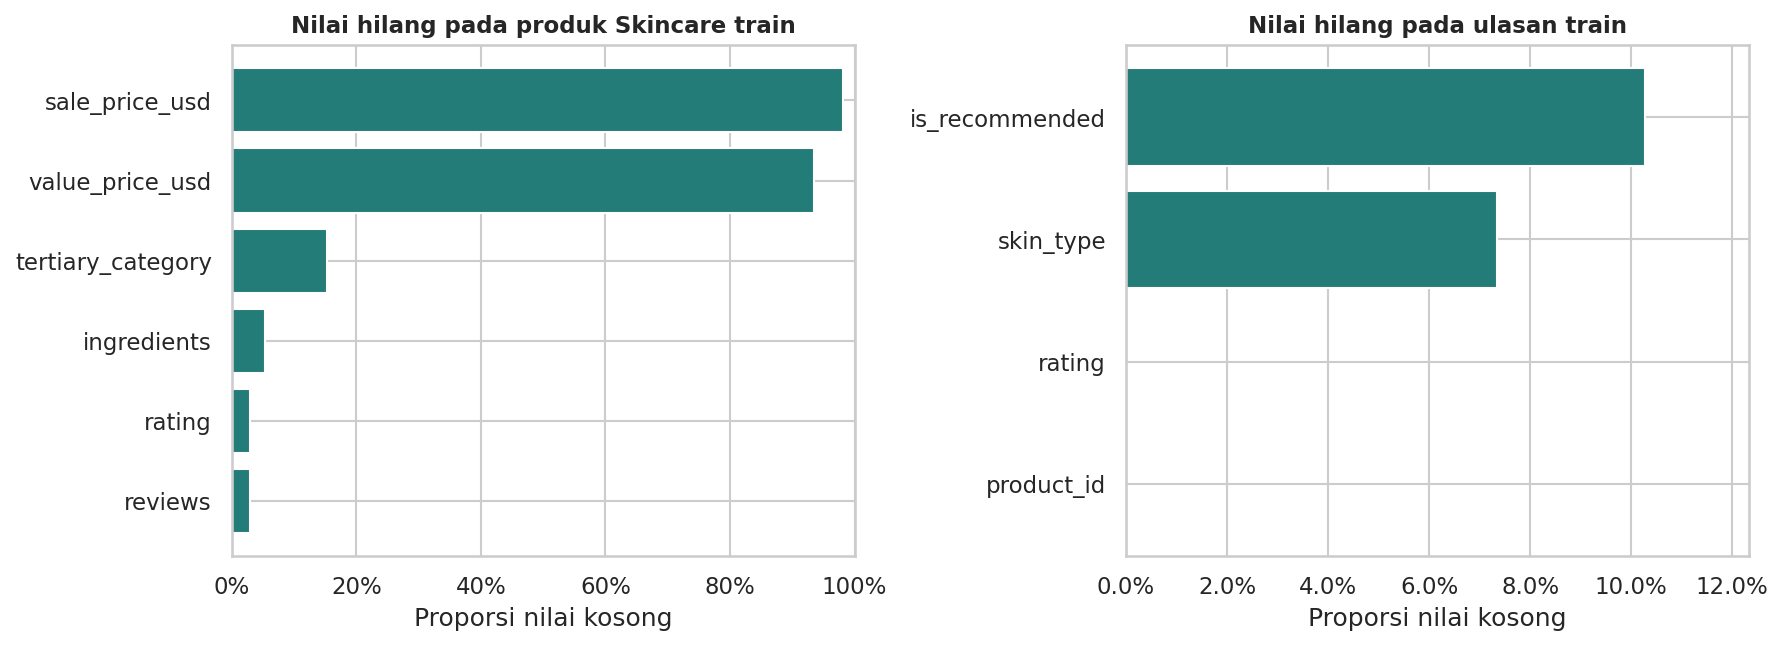

,kolom,proporsi_kosong
0,is_recommended,0.102703
1,skin_type,0.073441
2,rating,0.000000
3,product_id,0.000000


In [5]:
display(products_eda[['price_usd', 'rating', 'reviews', 'ingredient_count']].describe().round(2))
display(reviews_eda[['rating', 'is_recommended']].describe().round(3))
audit_types = pd.DataFrame({'kolom': reviews_eda.columns, 'tipe': reviews_eda.dtypes.astype(str).values,
                            'kosong': reviews_eda.isna().sum().values})
display(audit_types)
product_missing = products_eda[['ingredients', 'rating', 'reviews', 'tertiary_category', 'sale_price_usd', 'value_price_usd']].isna().mean().sort_values(ascending=False)
review_missing = reviews_eda[['skin_type', 'is_recommended', 'rating', 'product_id']].isna().mean().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, series, title in [(axes[0], product_missing, 'Nilai hilang pada produk Skincare train'),
                           (axes[1], review_missing, 'Nilai hilang pada ulasan train')]:
    ax.barh(series.index[::-1], series.values[::-1], color='#247C78')
    ax.set_xlim(0, min(1.0, max(0.12, float(series.max()) * 1.2)))
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel('Proporsi nilai kosong')
    ax.set_title(title, fontsize=11)
show_figure(fig)
show_table(pd.DataFrame({'kolom': review_missing.index, 'proporsi_kosong': review_missing.values}))

**Interpretasi visual 1.** Nilai kosong pada kolom harga diskon/nilai paket tidak berarti produk memiliki harga nol, melainkan atribut tersebut tidak selalu tersedia. Kolom itu tidak digunakan sebagai prediktor. Kekosongan `ingredients` dan `is_recommended` memengaruhi kelayakan baris untuk tujuan proyek; target kosong akan dikeluarkan. Jenis kulit kosong diberi kategori `unknown`, sehingga tidak dipaksakan menjadi jenis kulit mayoritas. Besarnya kekosongan aktual tercantum pada grafik dan tabel keluaran.

**Hasil terukur.** Pada train, target rekomendasi kosong sebesar 10.27%, jenis kulit kosong 7.34%, dan bahan katalog Skincare kosong 5.30%.

### 3.2 Jenis kulit dan keseimbangan target

Distribusi jenis kulit dihitung atas seluruh ulasan train, termasuk kategori yang belum diketahui. Distribusi target memisahkan label kosong dari kelas 0 dan 1. Proporsi kelas mayoritas adalah statistik data; angka itu bukan hasil pelatihan atau evaluasi model.

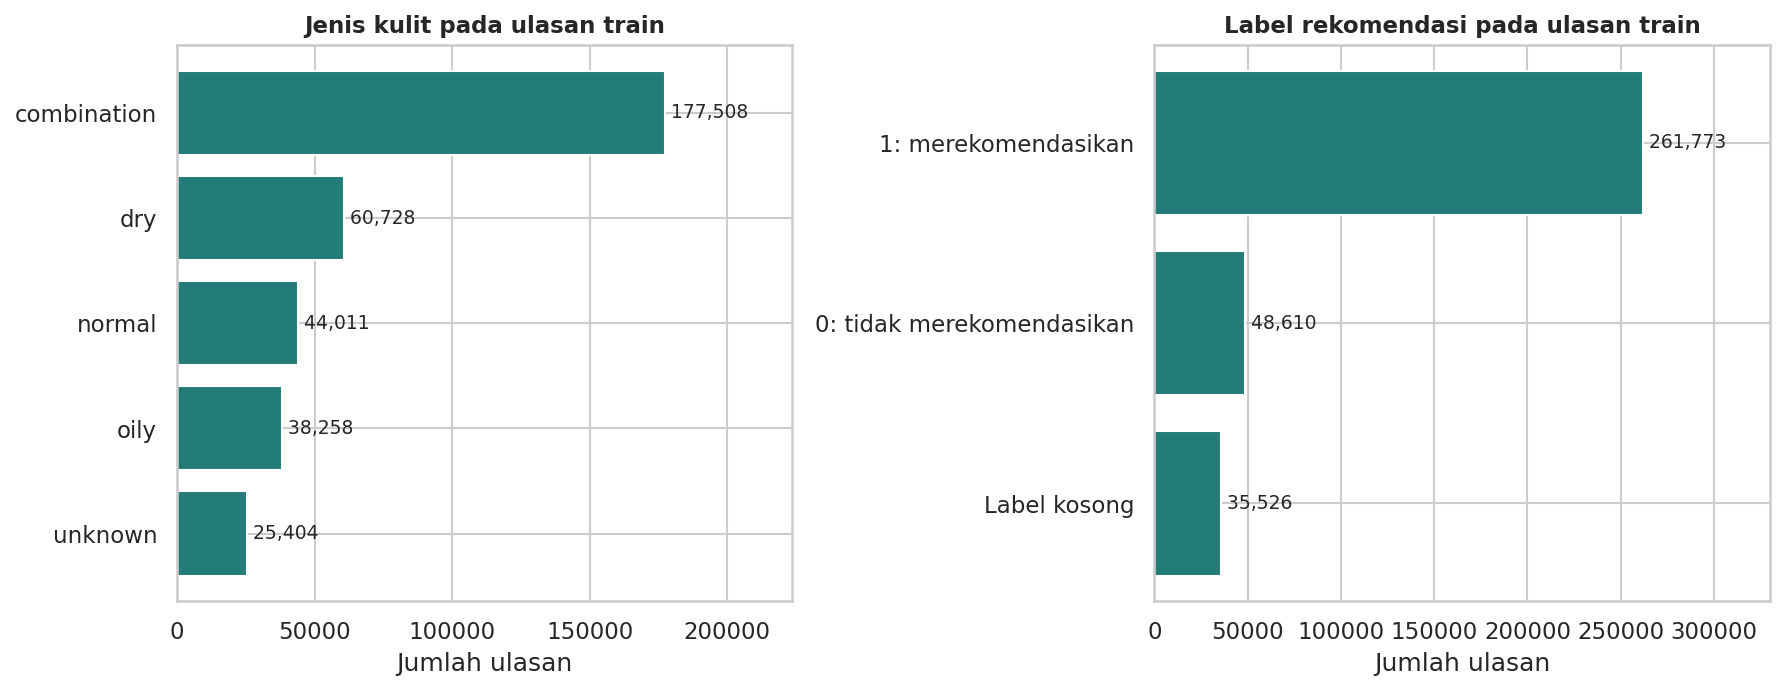

Proporsi label 1 di antara label valid train: 84.34%
Ini statistik kelas, bukan nilai akurasi model.


,skin_type,jumlah_ulasan
0,combination,177508
1,dry,60728
2,normal,44011
3,oily,38258
4,unknown,25404


In [6]:
skin_counts = reviews_eda['skin_type'].fillna('unknown').str.strip().str.lower().value_counts()
label_counts = reviews_eda['is_recommended'].map({0.0: '0: tidak merekomendasikan', 1.0: '1: merekomendasikan'}).fillna('Label kosong').value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for ax, counts, title in [(axes[0], skin_counts, 'Jenis kulit pada ulasan train'),
                          (axes[1], label_counts, 'Label rekomendasi pada ulasan train')]:
    bars = ax.barh(counts.index[::-1], counts.values[::-1], color='#247C78')
    for bar, value in zip(bars, counts.values[::-1]):
        ax.text(value, bar.get_y() + bar.get_height()/2, f' {value:,}', va='center', fontsize=9)
    ax.set_xlim(0, counts.max() * 1.26)
    ax.set_xlabel('Jumlah ulasan')
    ax.set_title(title, fontsize=11)
show_figure(fig)
valid_train_labels = reviews_eda.loc[reviews_eda['is_recommended'].isin([0, 1]), 'is_recommended']
train_positive_share = float(valid_train_labels.mean())
print(f'Proporsi label 1 di antara label valid train: {train_positive_share:.2%}')
print('Ini statistik kelas, bukan nilai akurasi model.')
show_table(skin_counts.rename_axis('skin_type').reset_index(name='jumlah_ulasan'))

**Interpretasi visual 2.** Jenis kulit yang paling sering dilaporkan dan label dominan dapat langsung dibandingkan pada grafik. Komposisi ulasan tidak membuktikan komposisi seluruh pelanggan Sephora karena hanya konsumen yang menulis ulasan yang masuk dataset. Dominasi label 1 membuat accuracy saja kurang memadai, sehingga Macro F1 dan recall kelas 0 direncanakan sebagai bagian evaluasi. Ketimpangan tidak ditangani dengan membuat ulasan sintetis; pembobotan kelas akan dipertimbangkan pada train saat tahap modelling.

**Hasil terukur.** Jenis kulit terbanyak adalah **combination**, sebanyak **177,508 ulasan (51.32%)**. Label 1 mencakup **84.34%** dari label valid train.

### 3.3 Kategori, harga, dan kandidat outlier

Distribusi harga menggunakan produk unik di katalog Skincare train. Harga ditafsirkan sebagai USD pada snapshot data, tanpa konversi ke rupiah atau klaim harga terkini. Batas IQR hanya menandai nilai ekstrem secara statistik; produk mahal yang valid tetap dipertahankan.

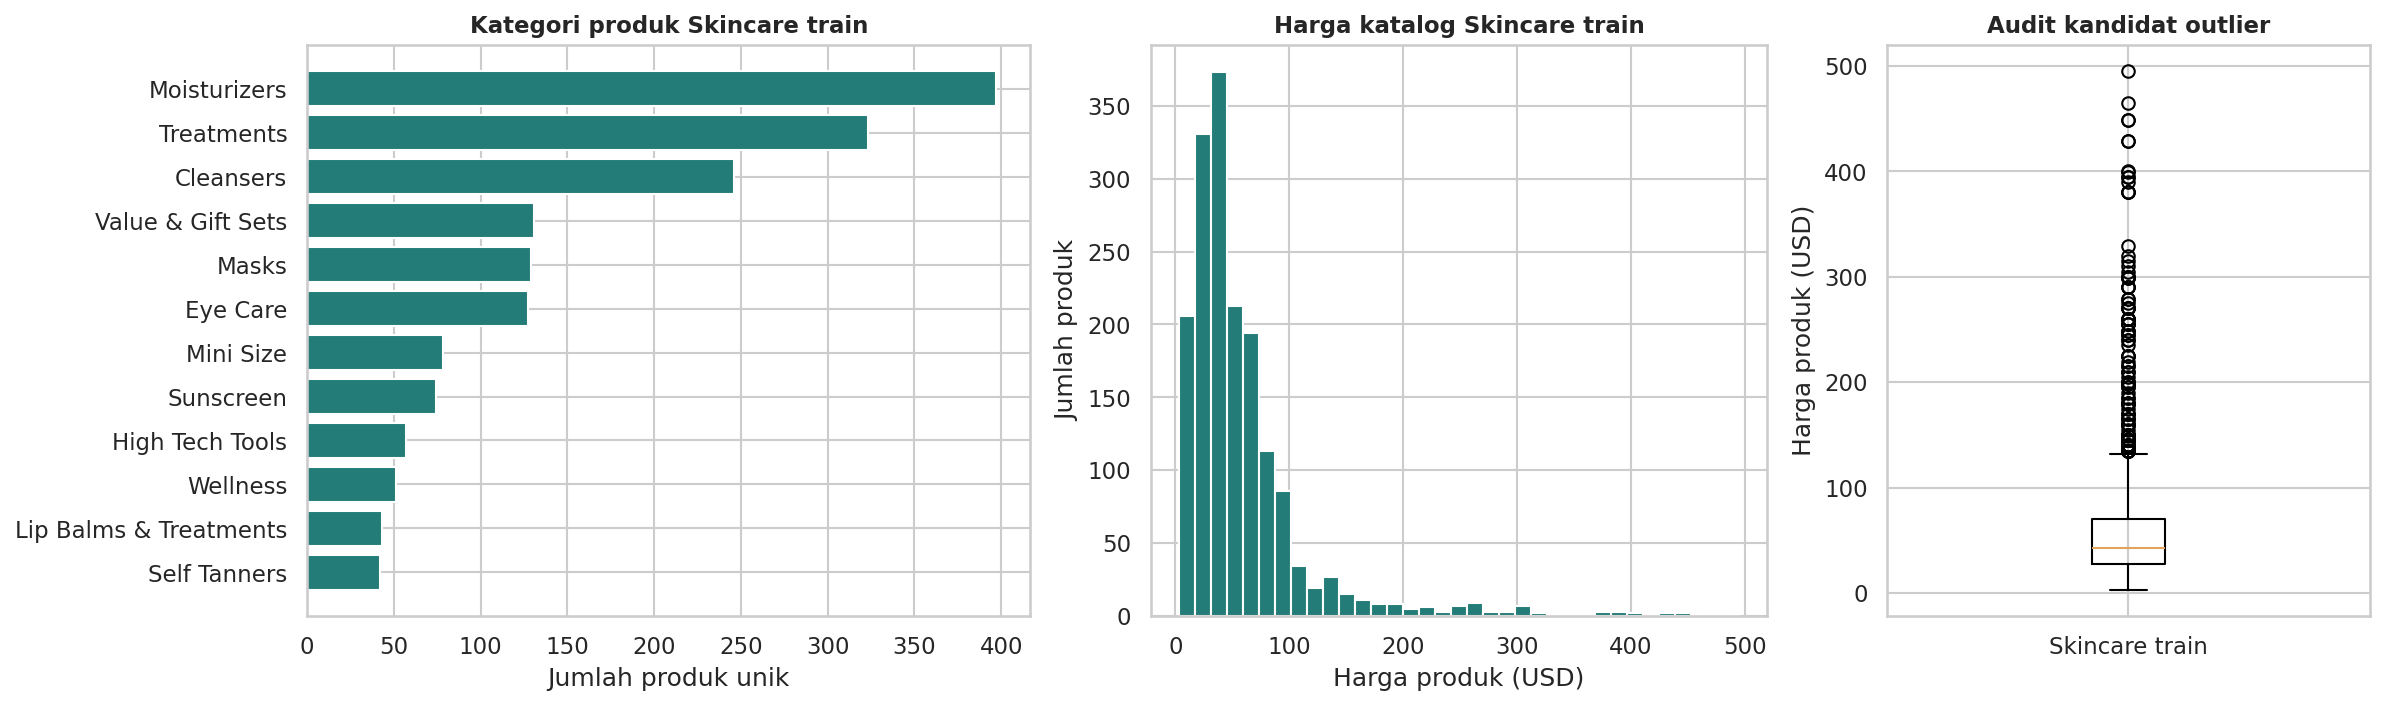

,q1_usd,q3_usd,batas_atas_iqr_usd,produk_ekstrem_iqr,harga_tidak_positif
0,28.0,70.0,133.0,116,0


,product_name,secondary_category,price_usd
5556,NuFACE Trinity+ & Effective Lip and Eye Attachment,High Tech Tools,495.0
2162,DRx SpectraLite BodyWare Pro,High Tech Tools,465.0
5545,Trinity + Eye and Lip Enhancer Attachment Bundle,High Tech Tools,449.0
5551,Trinity Facial Toning Device + Wrinkle Reducer Attachmen...,High Tech Tools,449.0
5553,Trinity Facial Toning Device + Wrinkle Reducer Attachmen...,High Tech Tools,429.0
5546,Trinity + Eye and Lip Enhancer Attachment Bundle,High Tech Tools,429.0
6937,Ultimate Revival Cream,Moisturizers,400.0
6799,Facial Sculpting Wand,High Tech Tools,399.0


In [7]:
category_counts = products_eda['secondary_category'].fillna('unknown').value_counts()
price = pd.to_numeric(products_eda['price_usd'], errors='coerce')
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5*iqr, q3 + 1.5*iqr
outlier_mask = (price < lower_bound) | (price > upper_bound)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1.35, 1.15, 0.9]})
axes[0].barh(category_counts.index[::-1], category_counts.values[::-1], color='#247C78')
axes[0].set_title('Kategori produk Skincare train', fontsize=11)
axes[0].set_xlabel('Jumlah produk unik')
axes[1].hist(price.dropna(), bins=35, color='#247C78', edgecolor='white')
axes[1].set_title('Harga katalog Skincare train', fontsize=11)
axes[1].set_xlabel('Harga produk (USD)')
axes[1].set_ylabel('Jumlah produk')
axes[2].boxplot(price.dropna(), vert=True, tick_labels=['Skincare train'])
axes[2].set_ylabel('Harga produk (USD)')
axes[2].set_title('Audit kandidat outlier', fontsize=11)
show_figure(fig)
display(pd.DataFrame([{'q1_usd': q1, 'q3_usd': q3, 'batas_atas_iqr_usd': upper_bound,
                       'produk_ekstrem_iqr': int(outlier_mask.sum()), 'harga_tidak_positif': int(price.le(0).sum())}]).round(2))
display(products_eda.loc[outlier_mask, ['product_name', 'secondary_category', 'price_usd']].sort_values('price_usd', ascending=False).head(8))

**Interpretasi visual 3.** Katalog mengandung kategori yang tidak setara dengan satu formula skincare, misalnya perangkat dan paket hadiah. Kategori tersebut akan dikeluarkan berdasarkan ruang lingkup, bukan karena memberi hasil label tertentu. Distribusi harga dan boxplot memperlihatkan rentang serta produk ekstrem. Nilai ekstrem yang masih positif dan berasal dari produk valid dipertahankan; menghapus semua produk di luar IQR berisiko menghilangkan segmen harga yang sah. Random Forest tidak mensyaratkan harga terdistribusi normal.

**Hasil terukur.** Median harga produk Skincare train adalah **USD 43.00**, dengan maksimum **USD 495.00**. Sebanyak **116 produk** ditandai sebagai kandidat outlier IQR dan tidak dihapus semata-mata karena ekstrem.

### 3.4 Rekomendasi menurut jenis kulit dan kategori

Tingkat rekomendasi adalah jumlah label 1 dibagi jumlah label valid. Visual heatmap memuat nilai proporsi serta ukuran sampel (`n`), agar persentase dari kelompok kecil tidak dibaca setara dengan kelompok besar. Sel dengan kurang dari 30 ulasan valid tidak ditampilkan. Batas 30 hanya aturan tampilan, bukan jaminan representativitas atau signifikansi.

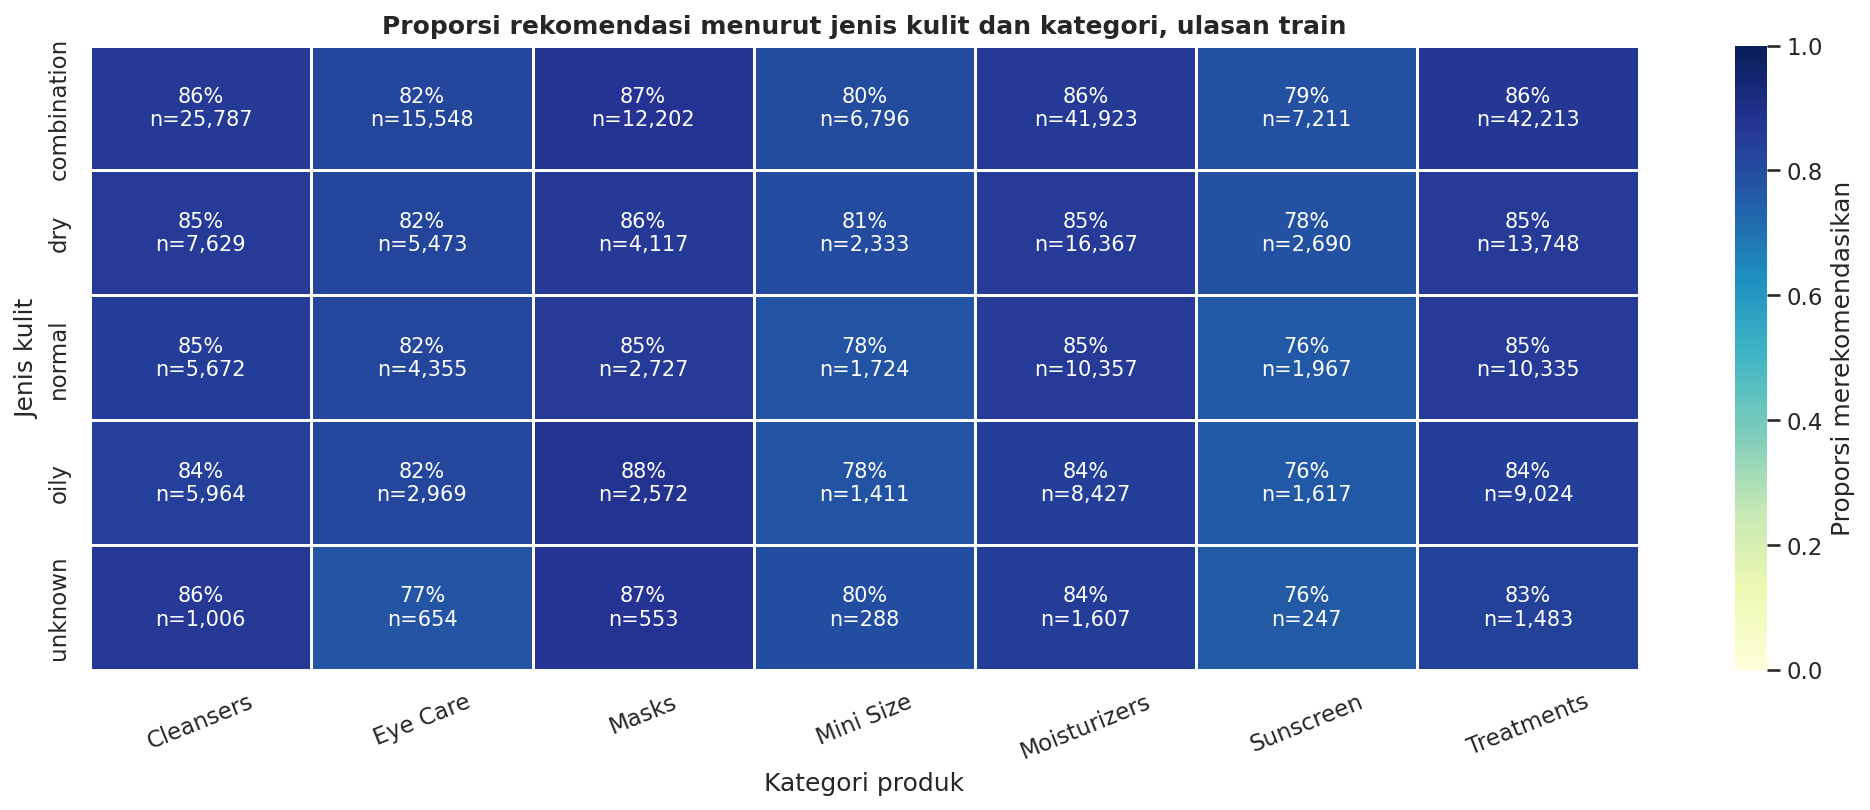

,skin_type,secondary_category,proporsi_rekomendasi,jumlah_label_valid
0,combination,Cleansers,0.8568,25787
1,combination,Eye Care,0.8213,15548
2,combination,Masks,0.8741,12202
3,combination,Mini Size,0.8031,6796
4,combination,Moisturizers,0.8574,41923
5,combination,Sunscreen,0.7916,7211
6,combination,Treatments,0.8646,42213
7,dry,Cleansers,0.8523,7629
8,dry,Eye Care,0.8213,5473
9,dry,Masks,0.8564,4117


In [8]:
eda_joined = reviews_eda.merge(
    products_eda[['product_id', 'secondary_category', 'price_usd']], on='product_id', how='left',
    validate='many_to_one', suffixes=('_review', '_product'),
)
eda_joined['skin_type'] = eda_joined['skin_type'].fillna('unknown').str.strip().str.lower()
eda_labeled = eda_joined[eda_joined['is_recommended'].isin([0, 1])].copy()
top_categories = eda_labeled['secondary_category'].value_counts().head(7).index
skin_order = ['combination', 'dry', 'normal', 'oily', 'unknown']
rates = eda_labeled[eda_labeled['secondary_category'].isin(top_categories)].groupby(['skin_type', 'secondary_category'])['is_recommended'].agg(['mean', 'size']).reset_index()
rate_matrix = rates.pivot(index='skin_type', columns='secondary_category', values='mean').reindex(skin_order)
count_matrix = rates.pivot(index='skin_type', columns='secondary_category', values='size').reindex_like(rate_matrix)
annotations = pd.DataFrame('', index=rate_matrix.index, columns=rate_matrix.columns)
for row in annotations.index:
    for column in annotations.columns:
        count = count_matrix.loc[row, column]
        if pd.notna(count) and count >= 30:
            annotations.loc[row, column] = f'{rate_matrix.loc[row, column]:.0%}\nn={int(count):,}'
fig, ax = plt.subplots(figsize=(13.7, 5.5))
sns.heatmap(rate_matrix, mask=count_matrix.lt(30) | count_matrix.isna(), annot=annotations, fmt='',
            cmap='YlGnBu', vmin=0, vmax=1, linewidths=0.6, ax=ax, cbar_kws={'label': 'Proporsi merekomendasikan'})
ax.set_title('Proporsi rekomendasi menurut jenis kulit dan kategori, ulasan train')
ax.set_xlabel('Kategori produk')
ax.set_ylabel('Jenis kulit')
ax.tick_params(axis='x', rotation=22)
show_figure(fig)
show_table(rates.rename(columns={'mean': 'proporsi_rekomendasi', 'size': 'jumlah_label_valid'}).round(4))

**Interpretasi visual 4.** Perbedaan persentase antar jenis kulit dan kategori merupakan hubungan deskriptif pada ulasan train. Pola ini mendukung penggunaan jenis kulit dan kategori sebagai calon fitur, tetapi belum membuktikan bahwa jenis kulit atau suatu bahan menyebabkan konsumen menyukai produk. Perbedaan produk, merek, harga, promosi, dan kecenderungan menulis ulasan dapat turut memengaruhi pola. Tidak ada uji signifikansi atau klaim sebab-akibat pada heatmap ini.

**Hasil terukur.** Pada sel berukuran minimal 30, proporsi tertinggi yang terlihat adalah **oily / Masks = 88.1% (n=2,572)**, sedangkan terendah **unknown / Sunscreen = 76.1% (n=247)**. Perbandingan ini deskriptif dan belum mengontrol komposisi produk.

### 3.5 Kandungan bahan dan ambiguitas formula

Bahan dihitung per **produk unik**, bukan per jumlah ulasan. Indikator berikut hanya menyatakan bahwa nama bahan/kelompok bahan terdeteksi pada daftar bahan. Kelompok ditetapkan dengan aturan pencocokan yang transparan, tidak dilabeli “baik/buruk” untuk suatu jenis kulit. Konsentrasi, kualitas formulasi, dan interaksi pemakaian tidak tersedia.

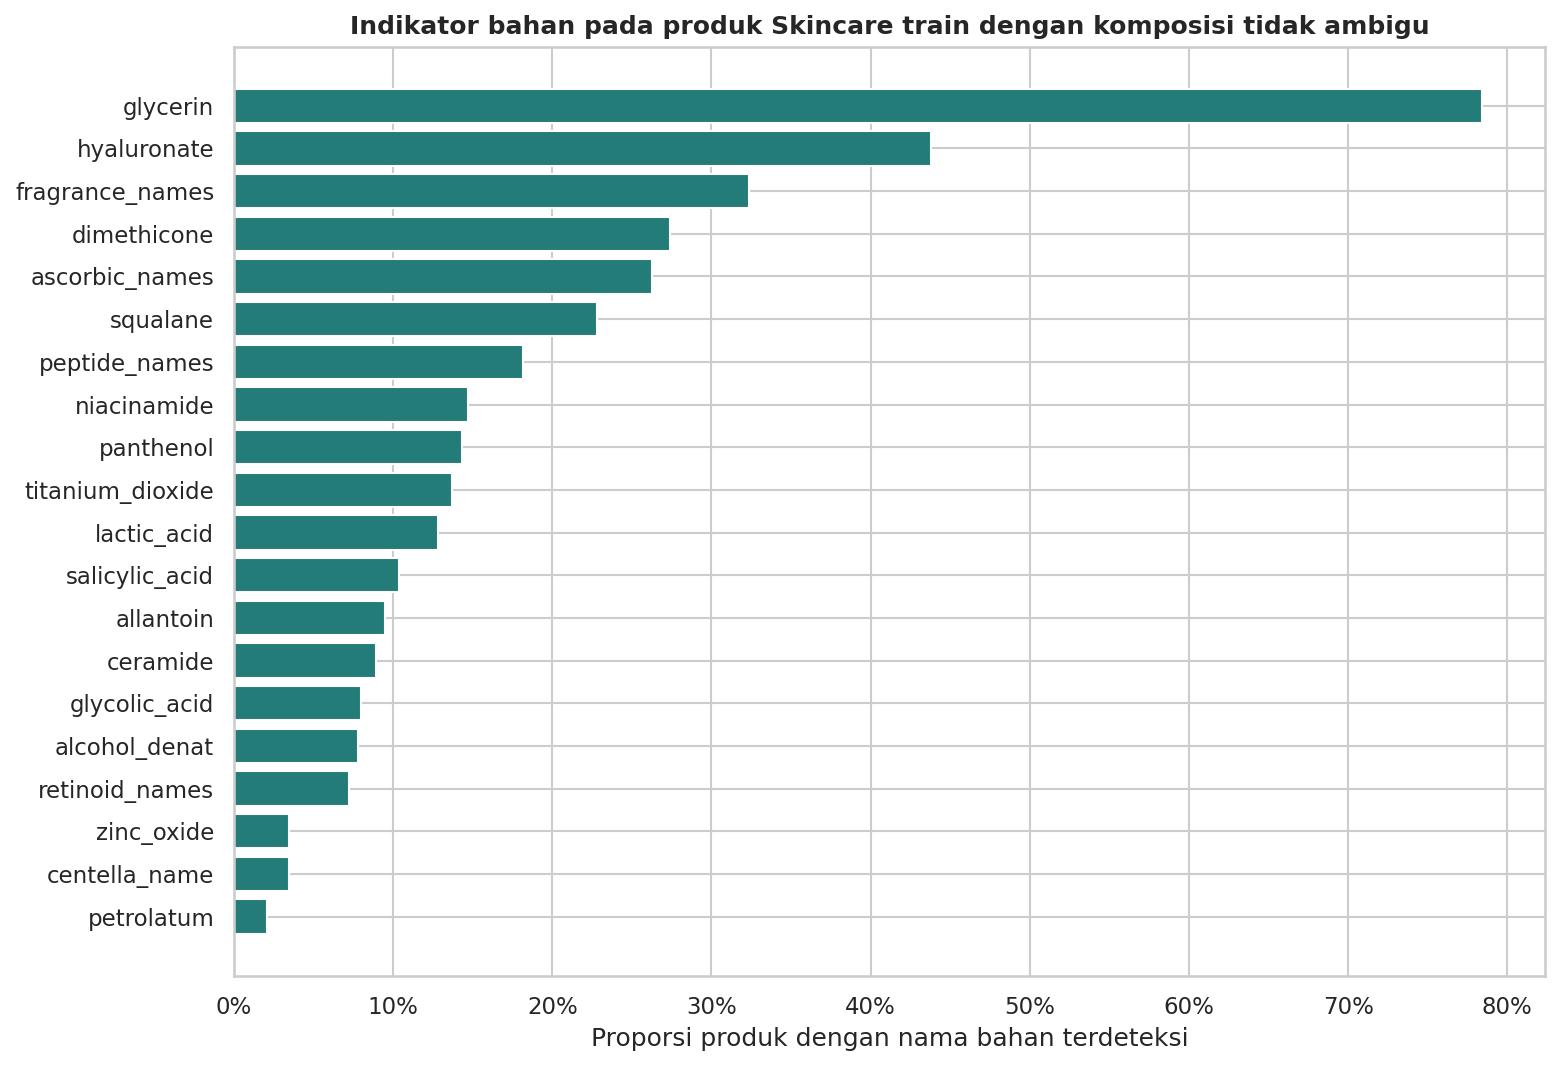

,parse_status,ambiguous_formula,jumlah_produk
0,list,False,1438
1,list,True,170
2,missing,False,90


,indikator,proporsi_produk
0,ing_petrolatum,0.0209
1,ing_centella_name,0.0348
2,ing_zinc_oxide,0.0348
3,ing_retinoid_names,0.0723
4,ing_alcohol_denat,0.0779
5,ing_glycolic_acid,0.0800
6,ing_ceramide,0.0890
7,ing_allantoin,0.0946
8,ing_salicylic_acid,0.1036
9,ing_lactic_acid,0.1280


In [9]:
# Pola dicocokkan dengan teks komposisi, bukan dengan nama produk atau teks ulasan.
INGREDIENT_PATTERNS = {
    'glycerin': r'\bglycerin\b|\bglycerol\b',
    'hyaluronate': r'\bhyaluronic acid\b|\b(?:sodium |potassium )?(?:acetylated )?hyaluronate\b',
    'niacinamide': r'\bniacinamide\b',
    'retinoid_names': r'\bretinol\b|\bretinal(?:dehyde)?\b|\bretinyl\b|\bhydroxypinacolone retinoate\b',
    'salicylic_acid': r'\bsalicylic acid\b',
    'glycolic_acid': r'\bglycolic acid\b',
    'lactic_acid': r'\blactic acid\b',
    'ceramide': r'\bceramide[s]?\b',
    'squalane': r'\bsqualane\b',
    'dimethicone': r'\bdimethicone\b',
    'petrolatum': r'\bpetrolatum\b',
    'peptide_names': r'\b[a-z0-9-]*peptide[a-z0-9-]*\b',
    'panthenol': r'\bpanthenol\b',
    'allantoin': r'\ballantoin\b',
    'centella_name': r'\bcentella asiatica\b',
    'ascorbic_names': r'\bascorbic acid\b|\b[a-z -]*ascorbyl [a-z]+\b|\b[a-z -]*ascorbate\b',
    'zinc_oxide': r'\bzinc oxide\b',
    'titanium_dioxide': r'\btitanium dioxide\b',
    'fragrance_names': r'\bfragrance\b|\bparfum\b',
    'alcohol_denat': r'\balcohol denat\b|\bdenatured alcohol\b|\bsd alcohol\b',
}
for name, pattern in INGREDIENT_PATTERNS.items():
    products['ing_' + name] = products['ingredients_text'].str.contains(pattern, regex=True).astype('uint8')
ingredient_columns = ['ing_' + name for name in INGREDIENT_PATTERNS]
eligible_for_ingredient_eda = products[products['split'].eq('train') & products['primary_category'].eq('Skincare')
                                      & products['ingredient_count'].gt(0) & ~products['ambiguous_formula']]
ingredient_prevalence = eligible_for_ingredient_eda[ingredient_columns].mean().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10.5, 7.2))
ax.barh([name.removeprefix('ing_') for name in ingredient_prevalence.index], ingredient_prevalence.values, color='#247C78')
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel('Proporsi produk dengan nama bahan terdeteksi')
ax.set_title('Indikator bahan pada produk Skincare train dengan komposisi tidak ambigu')
show_figure(fig)
display(products_eda.groupby(['parse_status', 'ambiguous_formula'], dropna=False).size().reset_index(name='jumlah_produk'))
show_table(pd.DataFrame({'indikator': ingredient_prevalence.index, 'proporsi_produk': ingredient_prevalence.values}).round(4))

**Interpretasi visual 5.** Grafik memperlihatkan kelompok bahan yang umum dan yang jarang terdeteksi dalam katalog train yang dapat dibaca. Sebuah produk dapat memiliki beberapa indikator sekaligus, sehingga proporsinya tidak perlu berjumlah 100%. Tidak ditemukannya suatu kelompok bahan berarti nama yang cocok dengan pola tidak terdeteksi; hasil ini bukan analisis laboratorium. Daftar pola dicantumkan langsung pada sel kode agar keputusan ekstraksi dapat ditinjau dan diperbaiki. Produk dengan beberapa formula tidak digabung menjadi satu komposisi karena ulasannya tidak menyebut varian yang pasti.

**Hasil terukur.** Tiga indikator paling sering terdeteksi pada populasi grafik adalah **glycerin (78.4%)**, **hyaluronate (43.8%)**, **fragrance_names (32.3%)**.

### 3.6 Audit label terhadap rating dan pengulangan profil

Rating ulasan memang berkaitan dengan `is_recommended`, tetapi rating itu baru diketahui setelah ulasan dibuat. Karena itu rating tidak boleh menjadi masukan sistem rekomendasi sebelum pembelian. Selain itu, banyak konsumen dapat memiliki jenis kulit sama, mengulas produk sama, dan memberi rating sama. Baris pada proyeksi yang terlihat identik tidak otomatis merupakan duplikat ulasan asli.

is_recommended,tidak_merekomendasikan,merekomendasikan
rating,,
1,17206,114
2,14134,521
3,15084,8478
4,1913,56438
5,273,196222


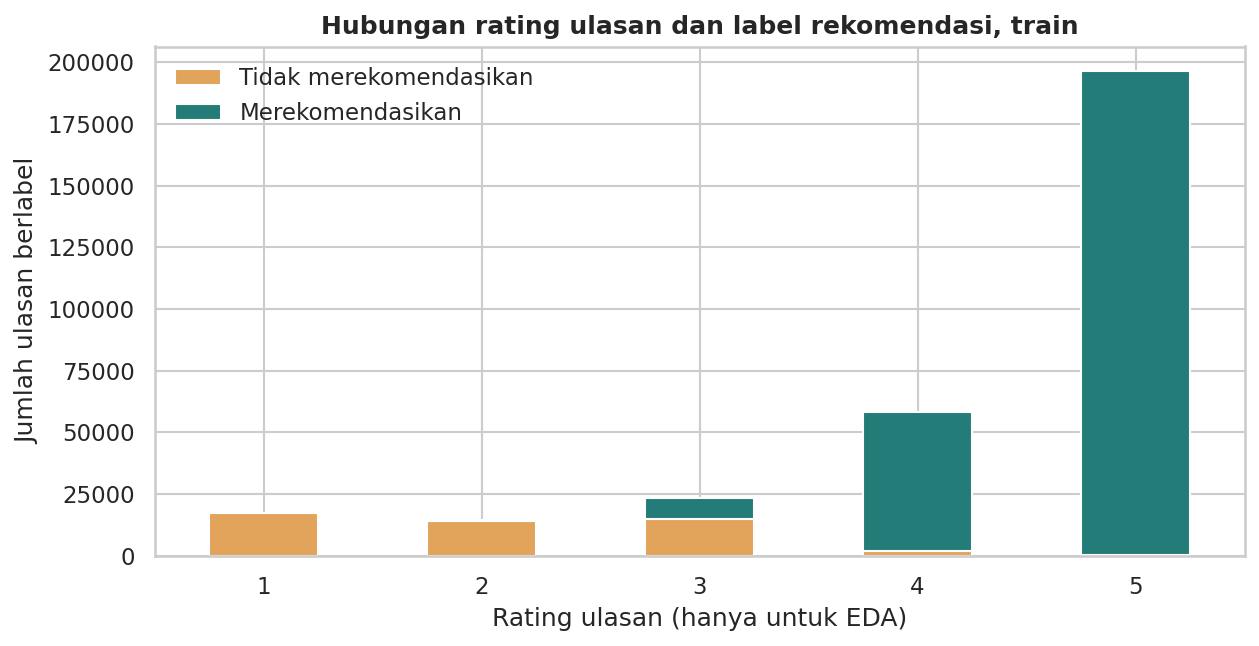

Pengulangan kombinasi empat atribut pada train: 316,793
Profil produk-jenis kulit dengan kedua label: 4826 dari 6578
Pengulangan proyeksi dipertahankan; identitas ulasan unik tidak tersedia pada proyeksi.


In [10]:
rating_cross = pd.crosstab(reviews_eda['rating'], reviews_eda['is_recommended']).reindex(index=[1, 2, 3, 4, 5], columns=[0.0, 1.0], fill_value=0)
display(rating_cross.rename(columns={0.0: 'tidak_merekomendasikan', 1.0: 'merekomendasikan'}))
fig, ax = plt.subplots(figsize=(8.5, 4.4))
rating_cross.plot(kind='bar', stacked=True, color=['#E2A35A', '#247C78'], ax=ax)
ax.set_title('Hubungan rating ulasan dan label rekomendasi, train')
ax.set_xlabel('Rating ulasan (hanya untuk EDA)')
ax.set_ylabel('Jumlah ulasan berlabel')
ax.legend(['Tidak merekomendasikan', 'Merekomendasikan'], frameon=False)
ax.tick_params(axis='x', rotation=0)
show_figure(fig)
projected_repetitions = int(reviews_eda.duplicated(subset=['product_id', 'skin_type', 'rating', 'is_recommended']).sum())
profile_conflict = eda_labeled.groupby(['product_id', 'skin_type'])['is_recommended'].agg(['nunique', 'size'])
print('Pengulangan kombinasi empat atribut pada train:', f'{projected_repetitions:,}')
print('Profil produk-jenis kulit dengan kedua label:', int(profile_conflict['nunique'].eq(2).sum()), 'dari', len(profile_conflict))
print('Pengulangan proyeksi dipertahankan; identitas ulasan unik tidak tersedia pada proyeksi.')

**Interpretasi visual 6.** Rating tinggi banyak disertai rekomendasi positif, tetapi tabulasi memperlihatkan label bukan sekadar hasil aturan rating. Karena itu label kosong tidak diisi dengan `rating >= 4`. Profil produk–jenis kulit dapat memuat dua keputusan berbeda; fitur yang sama tidak menjamin target sama. Hal ini membatasi prediksi personal dan menguatkan penafsiran skor sebagai kecenderungan kelompok. Baris proyeksi berulang tidak dihapus karena menghapusnya dapat mengubah distribusi ulasan asli.

**Hasil terukur.** Terdapat **635** ulasan train dengan rating 1–2 tetapi label 1, dan **2,186** dengan rating 4–5 tetapi label 0. Sebanyak **4,826 dari 6,578** profil produk–jenis kulit berlabel memuat kedua keputusan.

### 3.7 Ringkasan keputusan dari EDA

| Temuan / kebutuhan | Keputusan Cleaning dan Preprocessing |
| --- | --- |
| Katalog mencampur banyak kategori | Batasi Skincare, lalu keluarkan perangkat, wellness, paket hadiah, dan kategori lintas concern |
| Target kosong | Keluarkan dari dataset supervised; jangan mengarang label |
| Jenis kulit kosong | Simpan sebagai `unknown`, bukan imputasi jenis kulit mayoritas |
| Bahan kosong / parse gagal / formula beragam | Keluarkan dari kandidat pemodelan berbasis komposisi |
| Harga ekstrem tetapi valid | Pertahankan; hanya harga nonpositif/tidak numerik diperlakukan sebagai invalid |
| Produk/varian dapat berbagi formula | Group holdout menurut formula yang dinormalisasi |
| Label cenderung didominasi satu kelas | Rencanakan Macro F1, metrik per kelas, serta kajian pembobotan kelas |
| Proyeksi ulasan berulang | Pertahankan, kecuali duplikasi asal berkas-baris terbukti |
| Rating, metadata popularitas, teks ulasan tersedia setelah tanggapan | Keluarkan dari prediktor untuk mencegah kebocoran target |

## 4. Cleaning

### 4.1 Aturan penanganan

Cleaning memakai aturan berbasis makna kolom yang sama pada semua partisi. Parameter yang dipelajari, seperti median dan kategori encoder, baru di-fit pada train di Bagian 5.

1. Rapikan spasi ID/kategori dan pastikan satu ID produk memiliki satu metadata. Join menggunakan validasi `many_to_one`.
2. Fokus pada `primary_category = Skincare`. Keluarkan `Value & Gift Sets`, `High Tech Tools`, `Wellness`, dan `Shop by Concern` karena tidak mewakili satu formula produk topikal yang jelas.
3. Keluarkan daftar bahan kosong, parsing fallback yang tidak terverifikasi, dan daftar yang memuat header varian bertanda `:`. Pengecualian ini konservatif; beberapa produk yang sebenarnya dapat digunakan mungkin ikut keluar.
4. Pertahankan hanya target 0/1. Label kosong atau invalid dikeluarkan, tanpa imputasi berbasis rating.
5. Normalisasikan jenis kulit. Nilai kosong atau di luar empat kategori sumber menjadi `unknown`; jumlahnya dicatat. Produk valid dengan harga ekstrem tetap dipertahankan.
6. `source_file` dan `source_row` harus unik bersama-sama. Kesamaan empat atribut pada proyeksi tidak dijadikan alasan penghapusan ulasan.

Komposisi dan harga mengikuti snapshot katalog 2023, sedangkan ulasan bisa berasal dari formula sebelumnya. Hubungan ini tidak dapat dipastikan hanya dari `product_id`; keterbatasan tersebut dipertahankan dalam interpretasi.

In [11]:
EXCLUDED_SECONDARY = {'Value & Gift Sets', 'High Tech Tools', 'Wellness', 'Shop by Concern'}
VALID_SKIN_TYPES = {'combination', 'dry', 'normal', 'oily'}
product_clean = products.copy()
for column in ['brand_name', 'secondary_category', 'tertiary_category']:
    product_clean[column] = product_clean[column].map(normalize_text).replace('', 'unknown')
product_clean['price_usd'] = pd.to_numeric(product_clean['price_usd'], errors='coerce')
invalid_price_count = int(product_clean['price_usd'].le(0).sum())
product_clean.loc[product_clean['price_usd'].le(0), 'price_usd'] = np.nan
product_clean['price_missing'] = product_clean['price_usd'].isna().astype('uint8')
product_clean['eligible_scope'] = product_clean['primary_category'].eq('Skincare') & ~product_clean['secondary_category'].isin(EXCLUDED_SECONDARY)
product_clean['eligible_ingredients'] = (
    product_clean['ingredient_count'].gt(0) & ~product_clean['ambiguous_formula']
    & product_clean['parse_status'].isin(['list', 'plain_text', 'quoted_text'])
)
catalog_clean = product_clean[product_clean['eligible_scope'] & product_clean['eligible_ingredients']].copy()

review_clean = reviews_raw.copy()
raw_skin = review_clean['skin_type'].copy()
normalized_skin = raw_skin.fillna('unknown').map(normalize_text).str.lower()
unknown_skin_count = int((~normalized_skin.isin(VALID_SKIN_TYPES)).sum())
review_clean['skin_type'] = normalized_skin.where(normalized_skin.isin(VALID_SKIN_TYPES), 'unknown')
review_clean['is_recommended'] = pd.to_numeric(review_clean['is_recommended'], errors='coerce')

join_columns = ['product_id', 'product_name', 'brand_name', 'secondary_category', 'tertiary_category',
                'price_usd', 'price_missing', 'ingredient_count', 'ingredients_text', 'ingredient_tokens',
                'formula_group', 'eligible_scope', 'eligible_ingredients'] + ingredient_columns
joined = review_clean.merge(product_clean[join_columns], on='product_id', how='left', validate='many_to_one', indicator=True)
cleaning_steps = []
current = joined
def keep_rows(step, mask):
    global current
    before = len(current)
    current = current.loc[mask].copy()
    cleaning_steps.append({'tahap': step, 'sebelum': before, 'dikeluarkan': before-len(current), 'sesudah': len(current)})

keep_rows('Produk cocok dengan katalog', current['_merge'].eq('both'))
keep_rows('Kategori sesuai lingkup formula skincare', current['eligible_scope'].fillna(False))
keep_rows('Bahan terbaca dan tidak ambigu', current['eligible_ingredients'].fillna(False))
keep_rows('Target asli valid 0/1', current['is_recommended'].isin([0, 1]))
model_df = current.drop(columns=['_merge', 'eligible_scope', 'eligible_ingredients']).reset_index(drop=True)
model_df['is_recommended'] = model_df['is_recommended'].astype('uint8')
show_table(pd.DataFrame(cleaning_steps))
print('Harga katalog nonpositif yang ditandai invalid:', invalid_price_count)
print('Jenis kulit kosong/tidak dikenal yang diberi unknown (semua ulasan sumber):', f'{unknown_skin_count:,}')
print('Produk kandidat bersih (termasuk yang belum memiliki label valid):', len(catalog_clean))
print('Ulasan supervised siap diproses:', f'{len(model_df):,}')

,tahap,sebelum,dikeluarkan,sesudah
0,Produk cocok dengan katalog,492281,0,492281
1,Kategori sesuai lingkup formula skincare,492281,27074,465207
2,Bahan terbaca dan tidak ambigu,465207,15599,449608
3,Target asli valid 0/1,449608,45327,404281


Harga katalog nonpositif yang ditandai invalid: 0
Jenis kulit kosong/tidak dikenal yang diberi unknown (semua ulasan sumber): 36,874
Produk kandidat bersih (termasuk yang belum memiliki label valid): 1962
Ulasan supervised siap diproses: 404,281


### 4.2 Kondisi sebelum dan sesudah

Tabel alur di atas menghitung pengeluaran **secara berurutan**, sehingga setiap baris yang dikeluarkan dihitung sekali pada tahap pertama yang tidak dipenuhinya. Tabel berikut melengkapi audit tingkat katalog dan ulasan. Pengurangan jumlah baris adalah hasil aturan seleksi, bukan sampling acak untuk memperkecil dataset.

In [12]:
before_after = pd.DataFrame([
    ('Baris katalog', len(products_raw), len(catalog_clean)),
    ('Baris ulasan', len(reviews_raw), len(model_df)),
    ('ID produk katalog berulang', int(products_raw['product_id'].duplicated().sum()), int(catalog_clean['product_id'].duplicated().sum())),
    ('Target ulasan kosong/invalid', int((~reviews_raw['is_recommended'].isin([0, 1])).sum()), int((~model_df['is_recommended'].isin([0, 1])).sum())),
    ('Jenis kulit kosong', int(reviews_raw['skin_type'].isna().sum()), int(model_df['skin_type'].isna().sum())),
    ('Produk dengan komposisi kosong', int(products['ingredient_count'].eq(0).sum()), int(catalog_clean['ingredient_count'].eq(0).sum())),
    ('Produk dengan formula ambigu', int(products['ambiguous_formula'].sum()), int(catalog_clean['ambiguous_formula'].sum())),
], columns=['indikator', 'sebelum', 'sesudah'])
show_table(before_after)
numeric_model_columns = ['price_usd', 'price_missing', 'ingredient_count'] + ingredient_columns
category_model_columns = ['skin_type', 'brand_name', 'secondary_category', 'tertiary_category']
assert model_df['is_recommended'].isin([0, 1]).all()
assert model_df[category_model_columns].notna().all().all()
assert not model_df[['source_file', 'source_row']].duplicated().any()
assert catalog_clean['product_id'].is_unique
assert model_df['ingredient_count'].gt(0).all()
print('Audit target, kategori, asal baris, kunci produk, dan kelengkapan bahan: lulus.')

,indikator,sebelum,sesudah
0,Baris katalog,8494,1962
1,Baris ulasan,492281,404281
2,ID produk katalog berulang,0,0
3,Target ulasan kosong/invalid,50502,0
4,Jenis kulit kosong,36874,0
5,Produk dengan komposisi kosong,945,0
6,Produk dengan formula ambigu,1482,0


Audit target, kategori, asal baris, kunci produk, dan kelengkapan bahan: lulus.


## 5. Preprocessing dan Feature Selection

### 5.1 Fitur dipakai, dibuang, dan dibuat

Feature Selection tahap ini dilakukan **berdasarkan makna kolom, ketersediaan saat rekomendasi, dan risiko kebocoran**. Belum ada importance atau seleksi menggunakan model yang dilatih. Setiap indikator bahan berasal dari aturan tetap pada teks bahan katalog. Fitur ini memadatkan komposisi untuk mengendalikan jumlah fitur dan memudahkan penjelasan; senyawa di luar daftar pola belum direpresentasikan secara rinci.

| Kelompok | Keputusan dan alasan |
| --- | --- |
| `skin_type` | Dipakai: konteks jenis kulit; nilai kosong menjadi `unknown` |
| `brand_name`, `secondary_category`, `tertiary_category` | Dipakai dengan one-hot: konteks merek dan fungsi produk |
| `price_usd` | Dipakai: karakteristik harga; median train hanya bila ada nilai kosong/invalid |
| `price_missing`, `ingredient_count` | Dibuat dari sumber: menandai ketidaktersediaan harga dan panjang daftar bahan |
| 20 kolom `ing_*` | Dibuat: keberadaan nama kelompok bahan menurut regex yang didokumentasikan |
| `is_recommended` | Target, dipisahkan dari X |
| `product_id`, `formula_group`, `source_file`, `source_row`, `split` | Hanya metadata join/audit/partisi; tidak dimasukkan ke X |
| Rating ulasan; rata-rata rating/jumlah ulasan/loves katalog | Tidak dipakai dalam X: sinyal tanggapan/hasil setelah produk dinilai dan potensi kebocoran |
| Teks/judul ulasan dan atribut identitas/penampilan | Tidak dimuat; tidak tersedia saat rekomendasi dan tidak diperlukan untuk tujuan proyek |
| Nama produk, `highlights`, variasi/ukuran/harga diskon/status pemasaran | Tidak dipakai: identitas/teks promosi, semantik varian tidak pasti, atau konteks snapshot yang tidak diprioritaskan |
| `ingredients_text` dan token bahan | Bahan baku fitur serta metadata penjelasan/filter; tidak diberikan sebagai teks mentah ke Random Forest |

Daftar keputusan per kolom asli tercantum pada kamus data Bagian 2.4. Seluruh pola bahan tercantum dalam `INGREDIENT_PATTERNS` pada sel kode Bagian 3.5.

### 5.2 Menjaga batas partisi

Keanggotaan train/validation/test berasal dari split formula sebelum EDA dan tidak diacak kembali setelah melihat label. Setelah cleaning, jumlah baris dan kelompok tiap partisi dilaporkan. Pemisahan ini menguji generalisasi ke **produk/formula yang ditahan dari train**, bukan generalisasi ke penulis ulasan baru. Identitas penulis tidak dipakai, sehingga overlap orang tidak bisa diperiksa.

In [13]:
partition_frames = {name: model_df[model_df['split'].eq(name)].reset_index(drop=True)
                    for name in ['train', 'validation', 'test']}
for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert set(partition_frames[left]['formula_group']).isdisjoint(partition_frames[right]['formula_group'])
    assert set(partition_frames[left]['product_id']).isdisjoint(partition_frames[right]['product_id'])
split_summary = pd.DataFrame([
    {'partisi': name, 'ulasan': len(frame), 'produk': frame['product_id'].nunique(),
     'kelompok_formula': frame['formula_group'].nunique(), 'proporsi_ulasan': len(frame)/len(model_df)}
    for name, frame in partition_frames.items()
])
show_table(split_summary.round(4))
print('Overlap produk dan kelompok formula antar-partisi: 0.')
assert sum(len(frame) for frame in partition_frames.values()) == len(model_df)
for name, frame in partition_frames.items():
    assert frame['is_recommended'].nunique() == 2, f'Partisi {name} tidak memuat kedua kelas.'

,partisi,ulasan,produk,kelompok_formula,proporsi_ulasan
0,train,285887,1197,1118,0.7071
1,validation,60472,240,226,0.1496
2,test,57922,252,236,0.1433


Overlap produk dan kelompok formula antar-partisi: 0.


### 5.3 Encoding dan imputasi hanya dipelajari dari train

Kategori dinormalisasi menjadi string; nilai kosong telah ditandai `unknown`. `OneHotEncoder(handle_unknown='ignore')` di-fit **hanya pada kategori train** sehingga merek atau kategori baru tidak menimbulkan error pada validation/test. Kategori baru akan menghasilkan nol pada blok kategori terkait, sehingga informasi kategori itu menjadi terbatas; kejadian tersebut diaudit di bawah.

Fitur numerik menggunakan `SimpleImputer(strategy='median')` yang di-fit pada produk unik di train. Hal ini mencegah produk dengan banyak ulasan mengubah median harga. Harga tidak distandardisasi karena model pilihan berbasis pohon. Indikator biner bahan tetap 0/1. Komposisi yang tidak diketahui sudah dikeluarkan dan tidak diwakili seolah-olah semua bahannya tidak ada.

**`fit` pada imputer/encoder di sini adalah preprocessing. Tidak ada classifier yang dibuat atau dilatih.** Tidak ada resampling, SMOTE, atau pembuatan data sintetis.

In [14]:
FEATURES = numeric_model_columns + category_model_columns
TARGET = 'is_recommended'
forbidden_predictors = {'is_recommended', 'rating', 'rating_review', 'loves_count', 'reviews', 'product_id',
                        'author_id', 'review_text', 'review_title', 'formula_group', 'source_row', 'source_file', 'split'}
assert forbidden_predictors.isdisjoint(FEATURES)

X_frames = {name: frame[FEATURES].copy() for name, frame in partition_frames.items()}
y_arrays = {name: frame[TARGET].to_numpy(dtype=np.uint8) for name, frame in partition_frames.items()}
numeric_imputer = SimpleImputer(strategy='median')
train_unique_products = partition_frames['train'].drop_duplicates('product_id')
numeric_imputer.fit(train_unique_products[numeric_model_columns])
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=True, dtype=np.float32)
encoder.fit(X_frames['train'][category_model_columns].drop_duplicates())
feature_names = numeric_model_columns + encoder.get_feature_names_out(category_model_columns).tolist()

X_matrices = {}
unknown_categories = []
for name, frame in X_frames.items():
    numerical = sparse.csr_matrix(numeric_imputer.transform(frame[numeric_model_columns]).astype(np.float32))
    categorical = encoder.transform(frame[category_model_columns])
    X_matrices[name] = sparse.hstack([numerical, categorical], format='csr', dtype=np.float32)
    assert X_matrices[name].shape == (len(frame), len(feature_names))
    assert np.isfinite(X_matrices[name].data).all()
    for index, column in enumerate(category_model_columns):
        unseen = ~frame[column].isin(encoder.categories_[index])
        unknown_categories.append({'partisi': name, 'kolom': column, 'baris_kategori_baru': int(unseen.sum()),
                                   'kategori_baru_unik': int(frame.loc[unseen, column].nunique())})

matrix_summary = pd.DataFrame([
    {'partisi': name, 'baris': matrix.shape[0], 'fitur': matrix.shape[1],
     'nilai_non_nol': matrix.nnz, 'kepadatan': matrix.nnz/(matrix.shape[0]*matrix.shape[1]),
     'memori_mib': (matrix.data.nbytes+matrix.indices.nbytes+matrix.indptr.nbytes)/1024**2}
    for name, matrix in X_matrices.items()
])
show_table(matrix_summary.round(4))
show_table(pd.DataFrame(unknown_categories))
display(pd.DataFrame({'fitur_numerik': numeric_model_columns, 'median_train': numeric_imputer.statistics_}))
print('Fitur dasar sebelum encoding:', len(FEATURES))
print('Fitur akhir setelah encoding:', len(feature_names))
print('Preprocessing selesai. Classifier belum dibuat, dilatih, atau dievaluasi.')

,partisi,baris,fitur,nilai_non_nol,kepadatan,memori_mib
0,train,285887,180,2792806,0.0543,22.3980
1,validation,60472,180,581535,0.0534,4.6674
2,test,57922,180,561138,0.0538,4.5021


,partisi,kolom,baris_kategori_baru,kategori_baru_unik
0,train,skin_type,0,0
1,train,brand_name,0,0
2,train,secondary_category,0,0
3,train,tertiary_category,0,0
4,validation,skin_type,0,0
5,validation,brand_name,2386,3
6,validation,secondary_category,0,0
7,validation,tertiary_category,0,0
8,test,skin_type,0,0
9,test,brand_name,640,2


,fitur_numerik,median_train
0,price_usd,44.0
1,price_missing,0.0
2,ingredient_count,32.0
3,ing_glycerin,1.0
4,ing_hyaluronate,0.0
5,ing_niacinamide,0.0
6,ing_retinoid_names,0.0
7,ing_salicylic_acid,0.0
8,ing_glycolic_acid,0.0
9,ing_lactic_acid,0.0


Fitur dasar sebelum encoding: 27
Fitur akhir setelah encoding: 180
Preprocessing selesai. Classifier belum dibuat, dilatih, atau dievaluasi.


### 5.4 Audit akhir dan kesiapan data

Setelah seluruh sel dijalankan, `X_matrices`, `y_arrays`, `feature_names`, `preprocessing_config`, `model_export`, dan `catalog_clean` tersedia dalam memori untuk melanjutkan tahap modelling. Tabel dan grafik hasil eksekusi tertanam pada notebook. Dataset sumber yang diperlukan sudah disertakan pada folder `dataset/`, sehingga tidak dibutuhkan file konfigurasi, kamus data, gambar, atau skrip terpisah.

Sel berikut memeriksa kecocokan ukuran matriks dengan target dan daftar fitur, kemudian menampilkan contoh data siap pakai. Target tetap 0/1 asli. Hasil preprocessing tidak menambahkan data sintetis dan tidak melatih classifier. Pemeriksaan checksum sumber tercantum langsung pada sel pemuatan data.

In [15]:
# Hasil preprocessing berada di memori, tanpa ketergantungan berkas tambahan.
metadata_columns = ['source_file', 'source_row', 'product_id', 'formula_group', 'split']
model_export = model_df[metadata_columns + FEATURES + [TARGET]].copy()
preprocessing_config = {
    'random_state': RANDOM_STATE,
    'numeric_features': numeric_model_columns,
    'categorical_features': category_model_columns,
    'feature_names': feature_names,
    'median_train': dict(zip(numeric_model_columns, numeric_imputer.statistics_.tolist())),
    'encoder_categories': {column: values.tolist() for column, values in zip(category_model_columns, encoder.categories_)},
    'selected_method': 'Klasifikasi',
    'selected_model': 'Random Forest Classifier',
    'classifier_trained': False,
    'target': TARGET,
}
summary = {
    'products_raw': len(products_raw), 'reviews_raw': len(reviews_raw),
    'loaded_review_parts': len(loaded_originals), 'missing_review_files': missing_files,
    'catalog_clean': len(catalog_clean), 'model_rows': len(model_df),
    'base_features': len(FEATURES), 'encoded_features': len(feature_names),
    'train_positive_share_eda': train_positive_share,
    'split_summary': split_summary.to_dict('records'),
    'matrix_summary': matrix_summary.to_dict('records'),
    'cleaning_steps': cleaning_steps,
    'classifier_trained': False,
}
assert all(matrix.shape[0] == len(y_arrays[name]) for name, matrix in X_matrices.items())
assert all(matrix.shape[1] == len(feature_names) for matrix in X_matrices.values())
print('Dataset bersih, matriks X/y, daftar fitur, dan konfigurasi tersedia di memori setelah semua sel dijalankan.')
print('Tidak ada classifier yang dibuat, dilatih, atau dievaluasi.')
display(model_export.head())

Dataset bersih, matriks X/y, daftar fitur, dan konfigurasi tersedia di memori setelah semua sel dijalankan.
Tidak ada classifier yang dibuat, dilatih, atau dievaluasi.


,source_file,source_row,product_id,formula_group,split,price_usd,price_missing,ingredient_count,ing_glycerin,ing_hyaluronate,...,ing_ascorbic_names,ing_zinc_oxide,ing_titanium_dioxide,ing_fragrance_names,ing_alcohol_denat,skin_type,brand_name,secondary_category,tertiary_category,is_recommended
0,reviews_250-500.csv,0,P443842,formula_9206d7ff39c379431203a27b,train,12.99,0,31,1,1,...,1,0,0,0,0,combination,The INKEY List,Treatments,Face Serums,0
1,reviews_250-500.csv,1,P443842,formula_9206d7ff39c379431203a27b,train,12.99,0,31,1,1,...,1,0,0,0,0,normal,The INKEY List,Treatments,Face Serums,1
2,reviews_250-500.csv,2,P443842,formula_9206d7ff39c379431203a27b,train,12.99,0,31,1,1,...,1,0,0,0,0,combination,The INKEY List,Treatments,Face Serums,0
3,reviews_250-500.csv,3,P443842,formula_9206d7ff39c379431203a27b,train,12.99,0,31,1,1,...,1,0,0,0,0,combination,The INKEY List,Treatments,Face Serums,0
4,reviews_250-500.csv,4,P443842,formula_9206d7ff39c379431203a27b,train,12.99,0,31,1,1,...,1,0,0,0,0,combination,The INKEY List,Treatments,Face Serums,1


## 6. Pemilihan Model — Hanya Menentukan

### 6.1 Keputusan

**Metode: Klasifikasi. Model utama yang dipilih sebelum eksperimen: Random Forest Classifier.** Pilihan ini didasarkan pada struktur data dan kebutuhan interaksi jenis kulit–bahan. Ini adalah kandidat paling layak untuk rancangan sekarang, **belum merupakan pemenang empiris**. Penentuan model terbaik berdasarkan nilai metrik baru dapat dilakukan setelah tahap pelatihan dan evaluasi.

| Pilihan | Kesesuaian dengan masalah | Keputusan rancangan |
| --- | --- | --- |
| **Random Forest Classifier** | Menangkap interaksi nonlinier jenis kulit, bahan, kategori, dan harga; bekerja pada fitur campuran yang di-encode | **Dipilih sebagai model utama** |
| Decision Tree Classifier | Mudah divisualisasikan, tetapi satu pohon dapat sensitif terhadap data dan overfit | Alternatif pembanding jika diajarkan |
| Logistic Regression | Efisien dan transparan, tetapi interaksi jenis kulit–bahan harus dirancang eksplisit agar pengaruh bahan berbeda menurut jenis kulit | Alternatif jika diajarkan; perlu fitur interaksi tambahan |
| Clustering | Tidak langsung memakai label rekomendasi biner yang tersedia | Tidak dipilih sebagai metode utama |
| Regresi rating | Memerlukan target berbeda dari keputusan rekomendasi yang menjadi tujuan | Tidak dipilih |
| Forecasting | Tidak sesuai dengan tujuan prediksi keputusan ulasan berbasis fitur produk | Tidak dipilih |

Random Forest tetap memiliki risiko: model dapat mengandalkan merek, mengutamakan produk yang banyak diulas, dan memberi skor probabilitas yang perlu dikalibrasi. Banyak ulasan dengan profil fitur sama tetapi label berbeda menunjukkan preferensi personal belum terwakili sepenuhnya. Dataset dan fitur ini tidak cukup untuk menyimpulkan kecocokan klinis.

### 6.2 Rencana tahap berikutnya

Konfigurasi awal yang akan ditinjau pada validation: `n_estimators=200`, `max_depth=12`, `min_samples_leaf=20`, `max_features='sqrt'`, `random_state=42`. Nilai tersebut adalah **titik awal yang belum dijalankan**, bukan hasil tuning. `class_weight=None` dibandingkan dengan `'balanced_subsample'` hanya menggunakan train/validation, dengan memperhatikan bahwa pembobotan dapat mengubah interpretasi probabilitas. Pertimbangkan pembobotan per produk serta analisis hasil per jenis kulit. Tidak ada hyperparameter yang dinyatakan optimal pada tahap ini.

Data uji dikelompokkan berdasarkan formula dan tidak digunakan untuk tuning. Saat membandingkan beberapa algoritma, gunakan pembagian dan preprocessing yang sebanding. Model utama dinilai dari Macro F1 dan metrik pelengkap di Bagian 1, bukan accuracy semata. Kalibrasi dan Precision@5 ditambahkan hanya setelah model dan protokol relevansi ditetapkan.

Untuk Precision@5, rancangan sekunder adalah menghitung proporsi ulasan positif per produk–jenis kulit pada test, memakai minimal 10 ulasan valid dan ambang relevansi 80% yang ditetapkan terlebih dahulu. Ambang ini adalah definisi operasional, bukan hasil eksperimen; cakupan kandidat yang memenuhi syarat harus dilaporkan dan uji sensitivitas dilakukan pada validation. Tanpa identitas/riwayat pengguna, metrik tersebut hanya menilai pemeringkatan kelompok, bukan rekomendasi personal individual.

**Kepatuhan materi praktikum:** panduan hanya menilai model dari materi yang telah diajarkan. Daftar algoritma praktikum tidak disertakan, sehingga Random Forest harus dicocokkan dengan materi kelas sebelum implementasi. Notebook ini tidak mengklaim verifikasi materi telah selesai.

Referensi teknis primer: [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html), dan [Common pitfalls: data leakage](https://scikit-learn.org/stable/common_pitfalls.html).

## 7. Konklusi Sementara Milestone 30 Oktober

Kesimpulan di bawah menjawab pertanyaan awal sebatas bukti EDA dan kesiapan data. Tidak ada nilai prediksi, hasil evaluasi, atau klaim bahwa model sudah berhasil.

1. **Cakupan:** 8,494 produk katalog dan 492,281 ulasan dari 4/5 bagian berhasil dimuat. Bagian belum tersedia: `reviews_0-250.csv`. Pada train awal, jenis kulit terbanyak adalah combination dan proporsi label 1 di antara label valid mencapai 84.34%.
2. **Kualitas data:** target kosong/invalid tidak ditebak, jenis kulit kosong diberi unknown, dan produk dengan bahan kosong/ambigu dikeluarkan. Setelah aturan ruang lingkup, bahan, dan target diterapkan, tersisa **404,281 ulasan supervised**. Katalog kandidat bersih berisi **1,962 produk**, termasuk produk yang belum tentu memiliki ulasan berlabel.
3. **Pola ulasan:** proporsi rekomendasi berbeda menurut kombinasi jenis kulit dan kategori pada heatmap train. Ukuran sampel ikut dilaporkan. Pola ini mendukung calon fitur konteks kulit/kategori, tanpa membuktikan pengaruh sebab-akibat atau kecocokan medis.
4. **Representasi data:** bahan diubah menjadi 20 indikator pencocokan nama dan jumlah token. Bersama harga, penanda harga kosong, jenis kulit, merek, dan kategori, tersedia **27 fitur dasar** atau **180 fitur setelah encoding**. Imputer/encoder hanya dipelajari dari train. Produk dan grup formula tidak tumpang tindih antar-partisi.
5. **Keputusan metode/model:** **Klasifikasi dengan Random Forest Classifier sebagai pilihan awal**. Kelayakan empiris, metrik, serta model terbaik belum dapat dinyatakan sebelum eksperimen. Pelatihan dan evaluasi belum dilakukan sesuai cakupan permintaan.

| Partisi setelah cleaning | Ulasan | Produk unik | Kelompok formula |
| --- | --- | --- | --- |
| train | 285,887 | 1,197 | 1,118 |
| validation | 60,472 | 240 | 226 |
| test | 57,922 | 252 | 236 |

### Batasan dan pekerjaan berikutnya

- `reviews_0-250.csv` belum tersedia. Subset yang hilang dapat mengubah komposisi produk, kelas, dan jenis kulit, sehingga hasil tidak digeneralisasi menjadi seluruh dataset Kaggle.
- Data adalah snapshot katalog 2023 dan ulasan observasional. Harga, ketersediaan, dan formula produk saat ini dapat berubah.
- Jenis kulit dilaporkan sendiri dan tidak mencakup diagnosis. Kategori `unknown` bukan jenis kulit baru.
- Komposisi tidak memuat konsentrasi, urutan pemakaian, reaksi individu, atau keterkaitan varian ulasan yang pasti. Filter bahan akan bergantung pada ketepatan ekstraksi.
- Penulis ulasan tidak diidentifikasi. Penulis berulang, ulasan insentif, maupun overlap orang antar-partisi tidak dapat diperiksa; jumlah ulasan bukan jumlah konsumen unik.
- Kelompok formula mencegah overlap daftar bahan identik yang terdeteksi, tetapi perubahan ejaan atau formula hampir sama masih dapat luput. Split tidak menguji generalisasi kronologis.
- README memuat **usulan pembagian kontribusi**. Catatan kontribusi nyata harus diperbarui anggota berdasarkan pekerjaan dan commit masing-masing.

Sebelum pengumpulan tautan, cocokkan algoritma dengan materi praktikum serta catatan kelompok/dataset di spreadsheet kelas. Selanjutnya buat repository dari isi paket, lalu kirim tautannya pada Spada. Tahap modelling, evaluasi, dan konklusi akhir dilanjutkan sesuai tenggat 22 November 2026. Deployment tidak diperlukan oleh panduan.

### Referensi

1. Panduan Proyek Akhir Praktikum Data Science 2026/2027. Prodi Informatika UPN “Veteran” Yogyakarta. Dokumen lampiran, hlm. 2–5.
2. Inky, N. *Sephora Products and Skincare Reviews*. [Kaggle](https://www.kaggle.com/datasets/nadyinky/sephora-products-and-skincare-reviews). Metadata dan data card diakses 30 Oktober 2026; atribut lisensi dan metadata dicatat pada sel pemuatan data notebook ini.
3. Penerbit dataset. [Scraper Sephora](https://github.com/nadyinky/sephora-analysis/tree/main/sephora_scraper), sebagaimana ditautkan oleh data card.
4. scikit-learn developers. Dokumentasi resmi [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html), dan [pencegahan data leakage](https://scikit-learn.org/stable/common_pitfalls.html). Diakses 30 Oktober 2026.
5. [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/), tautan lisensi yang dinyatakan metadata penerbit. Atribusi dan perubahan subset dijelaskan pada Bagian 2 dan README.md.